Section 1 - Library Configuration

In [36]:

# ============================================================
# SECTION 1 — LIBRARIES AND CONFIGURATION
# ORIGINAL OR ALL-METRICS OCSVM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1.1 Select model version
# ------------------------------------------------------------

# Change to "all" for All-Metrics OCSVM and "original" for Original-metrics OCSVM.
MODEL_TYPE = "all"

if MODEL_TYPE not in ["original", "all"]:
    raise ValueError("MODEL_TYPE must be original or all")

DEVICES = ["Client1", "Client2", "Client3", "Switch"]

BASE_DIR = Path.cwd()
np.random.seed(42)

# ------------------------------------------------------------
# 1.2 Input files
# ------------------------------------------------------------

if MODEL_TYPE == "original":
    DATA_FILES = {
        "Client1": "Client1(original).csv",
        "Client2": "Client2(original).csv",
        "Client3": "Client3(original).csv",
        "Switch": "Switch(original).csv"
    }

    OUTPUT_DIR = BASE_DIR / "OCSVM_Original_Results"

else:
    DATA_FILES = {
        "Client1": "Client1(all).csv",
        "Client2": "Client2(all).csv",
        "Client3": "Client3(all).csv",
        "Switch": "Switch(all).csv"
    }

    OUTPUT_DIR = BASE_DIR / "OCSVM_All_Metrics_Results"

# ------------------------------------------------------------
# 1.3 Model configuration
# ------------------------------------------------------------

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

OCSVM_KERNEL = "rbf"
OCSVM_NU = 0.05
OCSVM_GAMMA = "scale"

ANOMALY_PERCENTILE = 99

# ------------------------------------------------------------
# 1.4 Original feature lists
# ------------------------------------------------------------

ORIGINAL_CLIENT_FEATURES = [
    "cpu_pct",
    "temperature_c",
    "temp_c",
    "latency_ms",
    "packet_loss_pct",
    "disk_usage_pct",
    "throughput_bytes_per_sec",
    "packet_error_rate_pct"
]

ORIGINAL_SWITCH_FEATURES = [
    "cpu_pct",
    "cpu_load",
    "free_memory",
    "free_ram",
    "temperature",
    "temp",
    "power_supply_state"
]

# ------------------------------------------------------------
# 1.5 Expanded feature lists
# ------------------------------------------------------------

ALL_CLIENT_FEATURES = [
    "cpu_pct",
    "temperature_c",
    "temp_c",
    "latency_ms",
    "packet_loss_pct",
    "reachability",
    "disk_usage_pct",
    "cpu_voltage_v",
    "power_supply_low_voltage",
    "cpu_speed_capped",
    "cpu_throttled",
    "cpu_clock_mhz",
    "est_power_draw_w",
    "throughput_bytes_per_sec",
    "packet_error_rate_pct"
]

ALL_SWITCH_FEATURES = [
    "cpu_pct",
    "cpu_load",
    "free_memory",
    "free_ram",
    "temperature",
    "temp",
    "power_supply_state"
]

# ------------------------------------------------------------
# 1.6 Output directories
# ------------------------------------------------------------

MODEL_DIR = OUTPUT_DIR / "Models"
CLEANED_DIR = OUTPUT_DIR / "Cleaned_Data"
RESULTS_DIR = OUTPUT_DIR / "Anomaly_Results"
EVENT_DIR = OUTPUT_DIR / "Anomaly_Events"
PLOTS_DIR = OUTPUT_DIR / "Plots"
FAULT_DIR = OUTPUT_DIR / "Fault_Injection"
EVAL_DIR = OUTPUT_DIR / "Final_Evaluation"

for folder in [
    MODEL_DIR,
    CLEANED_DIR,
    RESULTS_DIR,
    EVENT_DIR,
    PLOTS_DIR,
    FAULT_DIR,
    EVAL_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1.7 Find source files
# ------------------------------------------------------------

def locate_dataset(filename):

    matches = [
        p.resolve()
        for p in BASE_DIR.rglob(filename)
        if "Results" not in str(p.relative_to(BASE_DIR))
    ]

    if not matches:
        raise FileNotFoundError(
            f"Cannot find {filename} under {BASE_DIR}"
        )

    if len(matches) > 1:
        raise ValueError(
            f"Multiple matches for {filename}: {matches}"
        )

    return matches[0]

DATA_FILES = {
    device: locate_dataset(filename)
    for device, filename in DATA_FILES.items()
}

print("=" * 65)
print(f"SECTION 1 — {MODEL_TYPE.upper()} OCSVM")
print("=" * 65)

for device, path in DATA_FILES.items():
    print(device, ":", path)

print("Output:", OUTPUT_DIR.resolve())



SECTION 1 — ALL OCSVM
Client1 : C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Client1(all).csv
Client2 : C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Client2(all).csv
Client3 : C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Client3(all).csv
Switch : C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Switch(all).csv
Output: C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\OCSVM_All_Metrics_Results


Section 2 - Loading and cleaning

In [37]:

# ============================================================
# SECTION 2 — DATA LOADING AND PREPARATION
# ============================================================

datasets = {}
candidate_features = {}
cleaning_records = []

for device, path in DATA_FILES.items():

    print("\nProcessing:", device)

    df = pd.read_csv(path, low_memory=False)
    original_rows = len(df)

    # --------------------------------------------------------
    # 2.1 Find timestamp
    # --------------------------------------------------------

    time_col = next(
        (
            c for c in ["timestamp", "_time", "time"]
            if c in df.columns
        ),
        None
    )

    if time_col is None:
        raise ValueError(
            f"{device}: No timestamp column. "
            f"Available: {df.columns.tolist()}"
        )

    df = df.rename(columns={time_col: "timestamp"})

    df["timestamp"] = pd.to_datetime(
        df["timestamp"], utc=True, errors="coerce"
    )

    df = (
        df.dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    if df["timestamp"].duplicated().any():
        raise ValueError(
            f"{device}: Duplicate timestamps present"
        )

   
# ------------------------------------------------------------
# 2.2 Select all metrics except uptime
# ALL-METRICS OCSVM
# ------------------------------------------------------------

# Keep all telemetry columns except timestamps,
# uptime metrics and non-metric metadata.

exclude_columns = {
    "timestamp",
    "_time",
    "time",
    "device_id",
    "device_type",
    "collector_id",
    "metric_name",
    "unit",
    "method"
}

features = [
    col for col in df.columns
    if col.lower() not in exclude_columns
    and "uptime" not in col.lower()
]

# Do not remove constant or low-variability metrics.
# Do not remove original or expanded measurements.

features = list(dict.fromkeys(features))

if not features:
    raise ValueError(
        f"{device}: No telemetry metrics found."
    )

print(f"\n{device} — All-Metrics OCSVM")
print(f"Selected metrics: {len(features)}")

for metric in features:
    print(" -", metric)

    # --------------------------------------------------------
    # 2.3 Convert values to numeric
    # --------------------------------------------------------

    for col in features:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

    df = df[["timestamp"] + features].copy()

    # --------------------------------------------------------
    # 2.4 Missing-value handling
    # --------------------------------------------------------

    missing_before = int(
        df[features].isna().sum().sum()
    )

    # Keep chronological observations.
    # Missing values will be imputed using training-only
    # medians in Section 3 to prevent data leakage.

    for col in features:
        df[col] = df[col].replace(
            [np.inf, -np.inf], np.nan
        )

    if len(df) < 100:
        raise ValueError(
            f"{device}: Insufficient observations"
        )

    # --------------------------------------------------------
    # 2.5 Store prepared data
    # --------------------------------------------------------

    datasets[device] = df
    candidate_features[device] = features

    df.to_csv(
        CLEANED_DIR / f"{device}_Prepared.csv",
        index=False
    )

    cleaning_records.append({
        "Device": device,
        "Original_Rows": original_rows,
        "Prepared_Rows": len(df),
        "Candidate_Features": len(features),
        "Missing_Values": missing_before
    })

    print("Rows:", len(df))
    print("Features:", features)

cleaning_summary_df = pd.DataFrame(
    cleaning_records
)

cleaning_summary_df.to_csv(
    OUTPUT_DIR / "Cleaning_Summary.csv",
    index=False
)

print("\nSECTION 2 COMPLETE")



Processing: Client1

Processing: Client2

Processing: Client3

Processing: Switch

Switch — All-Metrics OCSVM
Selected metrics: 20
 - cpu_pct
Rows: 95844
Features: ['cpu_pct', 'free_memory', 'interface_1_in_bytes', 'interface_1_in_errors', 'interface_1_out_bytes', 'interface_1_out_errors', 'interface_2_in_bytes', 'interface_2_in_errors', 'interface_2_out_bytes', 'interface_2_out_errors', 'interface_3_in_bytes', 'interface_3_in_errors', 'interface_3_out_bytes', 'interface_3_out_errors', 'interface_4_in_bytes', 'interface_4_in_errors', 'interface_4_out_bytes', 'interface_4_out_errors', 'power_supply_state', 'temperature']
 - free_memory
Rows: 95844
Features: ['cpu_pct', 'free_memory', 'interface_1_in_bytes', 'interface_1_in_errors', 'interface_1_out_bytes', 'interface_1_out_errors', 'interface_2_in_bytes', 'interface_2_in_errors', 'interface_2_out_bytes', 'interface_2_out_errors', 'interface_3_in_bytes', 'interface_3_in_errors', 'interface_3_out_bytes', 'interface_3_out_errors', 'interf

section 3 - splitting and preprocessing

In [ ]:

# ============================================================
# loading dataset before secotion 3
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

datasets = {}
candidate_features = {}

for device in DEVICES:

    path = Path(DATA_FILES[device])

    if not path.exists():
        raise FileNotFoundError(path)

    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path, low_memory=False)
    else:
        df = pd.read_excel(path)

    time_col = next(
        (c for c in ["timestamp", "_time", "time"]
         if c in df.columns),
        None
    )

    if time_col is None:
        raise ValueError(
            f"{device}: Timestamp column not found. "
            f"Available: {df.columns.tolist()}"
        )

    df = df.rename(columns={time_col: "timestamp"})

    df["timestamp"] = pd.to_datetime(
        df["timestamp"], utc=True, errors="coerce"
    )

    df = (
        df.dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    # Keep all metrics except uptime and metadata
    excluded = {
        "timestamp", "_time", "time",
        "device_id", "device_type",
        "collector_id", "metric_name",
        "unit", "method"
    }

    features = [
        c for c in df.columns
        if c.lower() not in excluded
        and "uptime" not in c.lower()
    ]

    for col in features:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).replace([np.inf, -np.inf], np.nan)

    datasets[device] = df[["timestamp"] + features].copy()
    candidate_features[device] = features

    print(
        f"{device}: {len(df):,} rows, "
        f"{len(features)} metrics loaded"
    )

print("\nLoaded datasets:", list(datasets.keys()))
print("READY FOR SECTION 3")


Client1: 78,304 rows, 14 metrics loaded
Client2: 78,129 rows, 14 metrics loaded
Client3: 73,219 rows, 14 metrics loaded
Switch: 95,844 rows, 20 metrics loaded

Loaded datasets: ['Client1', 'Client2', 'Client3', 'Switch']
READY FOR SECTION 3


In [39]:
# ============================================================
# SECTION 3 — CHRONOLOGICAL SPLITTING AND SCALING
# ALL-METRICS OCSVM
# ============================================================

split_data = {}
scalers = {}
device_metrics = {}
split_records = []

for device in DEVICES:

    df = datasets[device]

    # --------------------------------------------------------
    # 3.1 Keep all metrics except uptime
    # --------------------------------------------------------

    features = [
        col for col in df.columns
        if col.lower() not in {
            "timestamp", "_time", "time",
            "device_id", "device_type",
            "collector_id", "metric_name",
            "unit", "method"
        }
        and "uptime" not in col.lower()
    ]

    for col in features:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).replace([np.inf, -np.inf], np.nan)

    device_metrics[device] = features

    # --------------------------------------------------------
    # 3.2 Chronological splitting
    # --------------------------------------------------------

    n = len(df)

    train_end = int(n * TRAIN_RATIO)
    val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

    train_df = df.iloc[:train_end].copy()
    val_df = df.iloc[train_end:val_end].copy()
    test_df = df.iloc[val_end:].copy()

    # --------------------------------------------------------
    # 3.3 Fill missing values using training medians
    # --------------------------------------------------------

    medians = train_df[features].median()

    if medians.isna().any():
        raise ValueError(
            f"{device}: Features with no valid training data: "
            f"{medians[medians.isna()].index.tolist()}"
        )

    X_train_raw = (
        train_df[features]
        .fillna(medians)
        .to_numpy(dtype=float)
    )

    X_val_raw = (
        val_df[features]
        .fillna(medians)
        .to_numpy(dtype=float)
    )

    X_test_raw = (
        test_df[features]
        .fillna(medians)
        .to_numpy(dtype=float)
    )

    # --------------------------------------------------------
    # 3.4 Scale using training data only
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train_raw)
    X_val = scaler.transform(X_val_raw)
    X_test = scaler.transform(X_test_raw)

    for X in [X_train, X_val, X_test]:
        if not np.isfinite(X).all():
            raise ValueError(
                f"{device}: Invalid values after scaling"
            )

    # --------------------------------------------------------
    # 3.5 Save results
    # --------------------------------------------------------

    scalers[device] = scaler

    split_data[device] = {
        "train": X_train,
        "val": X_val,
        "test": X_test,
        "train_timestamps": train_df["timestamp"],
        "val_timestamps": val_df["timestamp"],
        "test_timestamps": test_df["timestamp"],
        "metrics": features,
        "fill_values": medians
    }

    split_records.append({
        "Device": device,
        "Train": len(X_train),
        "Validation": len(X_val),
        "Test": len(X_test),
        "Features": len(features)
    })

    print(f"\n{device}")
    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Test:", X_test.shape)
    print("Features used:", features)

# ------------------------------------------------------------
# 3.6 Save summary
# ------------------------------------------------------------

split_summary_df = pd.DataFrame(split_records)

split_summary_df.to_csv(
    OUTPUT_DIR / "Split_Summary.csv",
    index=False
)

print("\nSECTION 3 COMPLETE")



Client1
Train: (54812, 14)
Validation: (11746, 14)
Test: (11746, 14)
Features used: ['cpu_clock_mhz', 'cpu_pct', 'cpu_speed_capped', 'cpu_throttled', 'cpu_voltage_v', 'disk_usage_pct', 'est_power_draw_w', 'latency_ms', 'packet_error_rate_pct', 'packet_loss_pct', 'power_supply_low_voltage', 'reachability', 'temperature_c', 'throughput_bytes_per_sec']

Client2
Train: (54690, 14)
Validation: (11719, 14)
Test: (11720, 14)
Features used: ['cpu_clock_mhz', 'cpu_pct', 'cpu_speed_capped', 'cpu_throttled', 'cpu_voltage_v', 'disk_usage_pct', 'est_power_draw_w', 'latency_ms', 'packet_error_rate_pct', 'packet_loss_pct', 'power_supply_low_voltage', 'reachability', 'temperature_c', 'throughput_bytes_per_sec']

Client3
Train: (51253, 14)
Validation: (10983, 14)
Test: (10983, 14)
Features used: ['cpu_clock_mhz', 'cpu_pct', 'cpu_speed_capped', 'cpu_throttled', 'cpu_voltage_v', 'disk_usage_pct', 'est_power_draw_w', 'latency_ms', 'packet_error_rate_pct', 'packet_loss_pct', 'power_supply_low_voltage', 'r

Section 4 - feature verification

In [40]:

# ============================================================
# SECTION 4 — FEATURE VERIFICATION
# ============================================================

feature_records = []

for device in DEVICES:

    data = split_data[device]
    metrics = data["metrics"]

    for split_name in ["train", "val", "test"]:

        X = data[split_name]

        assert X.ndim == 2
        assert X.shape[1] == len(metrics)
        assert np.isfinite(X).all()

    feature_records.append({
        "Device": device,
        "Feature_Count": len(metrics),
        "Features": ", ".join(metrics)
    })

    print(f"\n{device}")
    print("Number of features:", len(metrics))
    print("Features:", metrics)

pd.DataFrame(feature_records).to_csv(
    OUTPUT_DIR / "Feature_Summary.csv",
    index=False
)

print("\nSECTION 4 COMPLETE")



Client1
Number of features: 14
Features: ['cpu_clock_mhz', 'cpu_pct', 'cpu_speed_capped', 'cpu_throttled', 'cpu_voltage_v', 'disk_usage_pct', 'est_power_draw_w', 'latency_ms', 'packet_error_rate_pct', 'packet_loss_pct', 'power_supply_low_voltage', 'reachability', 'temperature_c', 'throughput_bytes_per_sec']

Client2
Number of features: 14
Features: ['cpu_clock_mhz', 'cpu_pct', 'cpu_speed_capped', 'cpu_throttled', 'cpu_voltage_v', 'disk_usage_pct', 'est_power_draw_w', 'latency_ms', 'packet_error_rate_pct', 'packet_loss_pct', 'power_supply_low_voltage', 'reachability', 'temperature_c', 'throughput_bytes_per_sec']

Client3
Number of features: 14
Features: ['cpu_clock_mhz', 'cpu_pct', 'cpu_speed_capped', 'cpu_throttled', 'cpu_voltage_v', 'disk_usage_pct', 'est_power_draw_w', 'latency_ms', 'packet_error_rate_pct', 'packet_loss_pct', 'power_supply_low_voltage', 'reachability', 'temperature_c', 'throughput_bytes_per_sec']

Switch
Number of features: 20
Features: ['cpu_pct', 'free_memory', 'i

Section 5 - train OCSVM models and calculating the thresholds

In [41]:
# ============================================================
# SECTION 5 — TRAIN OCSVM MODELS
# ============================================================

models = {}
anomaly_thresholds = {}
training_records = []

for device in DEVICES:

    print("\nTraining:", device)

    data = split_data[device]

    model = OneClassSVM(
        kernel=OCSVM_KERNEL,
        nu=OCSVM_NU,
        gamma=OCSVM_GAMMA
    )

    # --------------------------------------------------------
    # 5.1 Train
    # --------------------------------------------------------

    model.fit(data["train"])

    # --------------------------------------------------------
    # 5.2 Calculate validation threshold
    # --------------------------------------------------------

    train_scores = -model.decision_function(
        data["train"]
    ).ravel()

    val_scores = -model.decision_function(
        data["val"]
    ).ravel()

    threshold = float(
        np.percentile(
            val_scores,
            ANOMALY_PERCENTILE
        )
    )

    models[device] = model
    anomaly_thresholds[device] = threshold

    # --------------------------------------------------------
    # 5.3 Save model and preprocessing
    # --------------------------------------------------------

    joblib.dump(
        {
            "model": model,
            "scaler": scalers[device],
            "features": data["metrics"],
            "fill_values": data["fill_values"],
            "threshold": threshold
        },
        MODEL_DIR / f"{device}_OCSVM.joblib"
    )

    training_records.append({
        "Device": device,
        "Train_Samples": len(data["train"]),
        "Validation_Samples": len(data["val"]),
        "Support_Vectors": len(model.support_),
        "Threshold": threshold,
        "Train_Mean_Score": train_scores.mean(),
        "Validation_Mean_Score": val_scores.mean()
    })

    print("Threshold:", threshold)
    print("Support vectors:", len(model.support_))

training_summary_df = pd.DataFrame(
    training_records
)

training_summary_df.to_csv(
    OUTPUT_DIR / "Training_Summary.csv",
    index=False
)

print("\nSECTION 5 COMPLETE")



Training: Client1
Threshold: 90.22552632411633
Support vectors: 2751

Training: Client2
Threshold: 116.16901454901883
Support vectors: 2748

Training: Client3
Threshold: 96.41034957724655
Support vectors: 2583

Training: Switch
Threshold: 243.0226552602971
Support vectors: 3363

SECTION 5 COMPLETE


Section 6 - Anomaly detection and metrics attrbutions

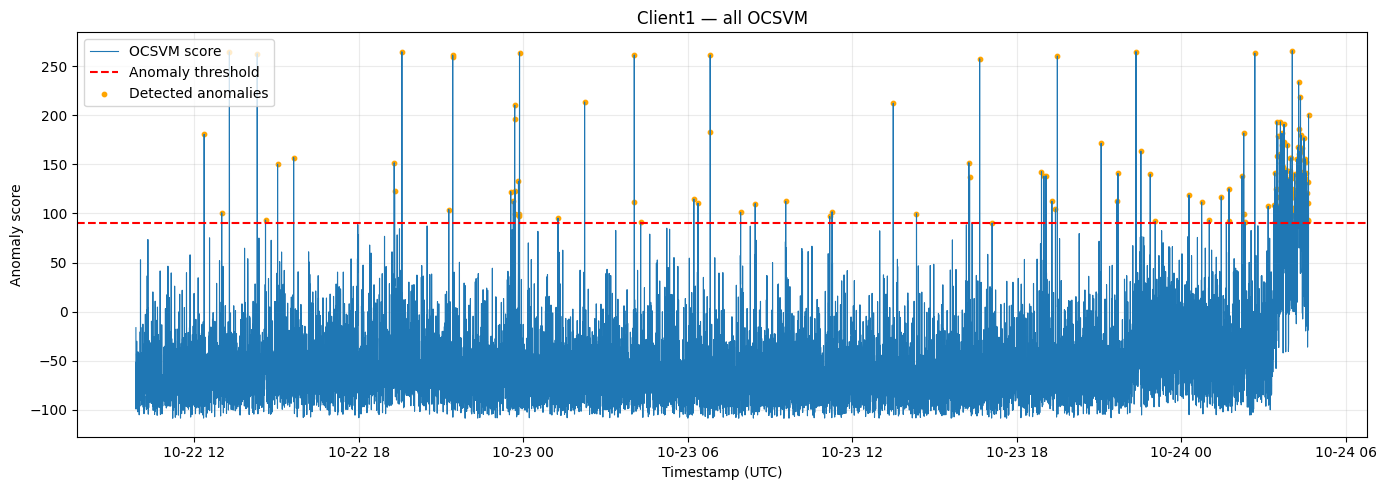

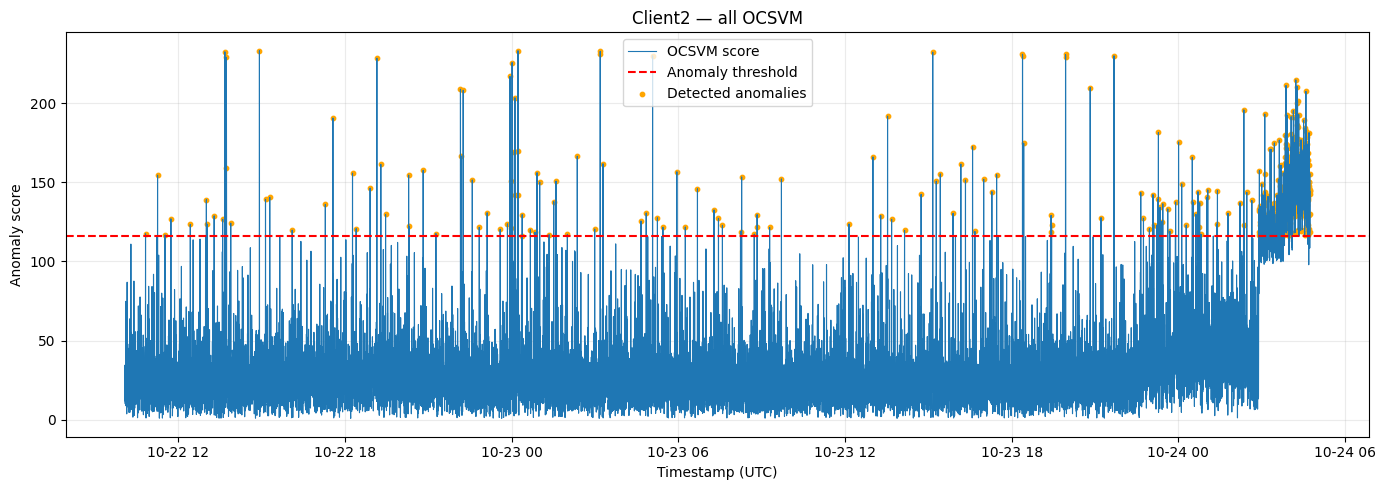

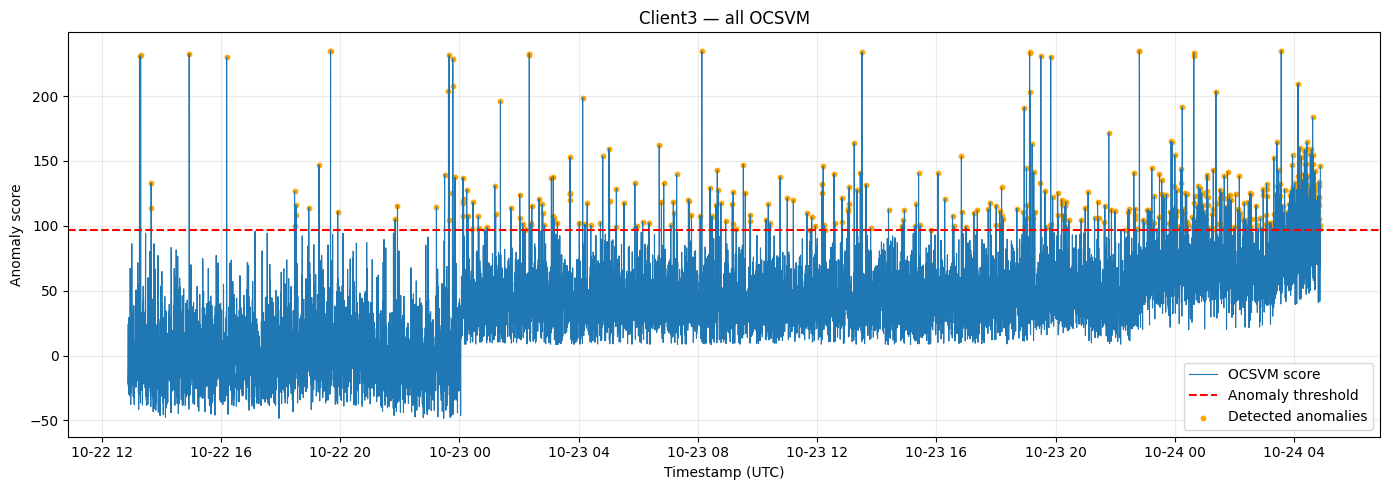

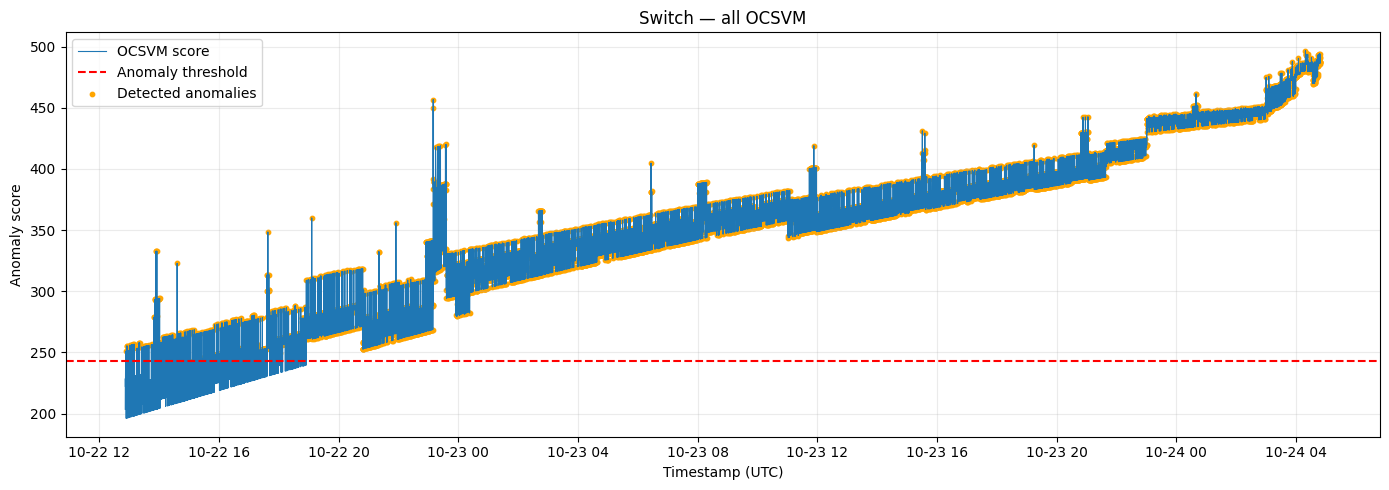


SECTION 6 COMPLETE
 Device  Test_Samples  Anomalous_Samples  Anomaly_Rate_Pct  Threshold  Mean_Score  Maximum_Score
Client1         11746                208          1.770816  90.225526  -53.106847     265.833794
Client2         11720                525          4.479522 116.169015   34.082859     233.168251
Client3         10983                537          4.889374  96.410350   37.346488     234.993960
 Switch         14377              13233         92.042846 243.022655  349.425467     496.622474


In [42]:
# ============================================================
# SECTION 6 — TEST ANOMALY DETECTION
# ============================================================

anomaly_results = {}
evaluation_records = []

for device in DEVICES:

    data = split_data[device]
    X = data["test"]
    model = models[device]
    threshold = anomaly_thresholds[device]
    features = data["metrics"]

    # --------------------------------------------------------
    # 6.1 Test scores
    # --------------------------------------------------------

    scores = -model.decision_function(X).ravel()
    flags = scores > threshold

    # --------------------------------------------------------
    # 6.2 Most unusual metric
    # --------------------------------------------------------

    # Largest absolute z-score. This is explanatory
    # attribution, not exact OCSVM feature importance.

    abs_z = np.abs(X)

    unusual_indices = np.argmax(abs_z, axis=1)

    unusual_metrics = [
        features[i] for i in unusual_indices
    ]

    unusual_values = abs_z[
        np.arange(len(X)),
        unusual_indices
    ]

    # --------------------------------------------------------
    # 6.3 Save anomaly results
    # --------------------------------------------------------

    results = pd.DataFrame({
        "timestamp": pd.to_datetime(
            data["test_timestamps"], utc=True
        ).to_numpy(),
        "anomaly_score": scores,
        "threshold": threshold,
        "is_anomaly": flags,
        "most_unusual_metric": unusual_metrics,
        "most_unusual_metric_abs_z": unusual_values
    })

    for i, feature in enumerate(features):
        results[f"{feature}_abs_z"] = abs_z[:, i]

    anomaly_results[device] = results

    results.to_csv(
        RESULTS_DIR / f"{device}_Anomaly_Results.csv",
        index=False
    )

    # --------------------------------------------------------
    # 6.4 Evaluation summary
    # --------------------------------------------------------

    evaluation_records.append({
        "Device": device,
        "Test_Samples": len(results),
        "Anomalous_Samples": int(flags.sum()),
        "Anomaly_Rate_Pct": flags.mean() * 100,
        "Threshold": threshold,
        "Mean_Score": scores.mean(),
        "Maximum_Score": scores.max()
    })

    # --------------------------------------------------------
    # 6.5 Plot anomaly scores
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        results["timestamp"],
        scores,
        linewidth=0.8,
        label="OCSVM score"
    )

    ax.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="Anomaly threshold"
    )

    ax.scatter(
        results.loc[flags, "timestamp"],
        scores[flags],
        color="orange",
        s=10,
        label="Detected anomalies"
    )

    ax.set_title(f"{device} — {MODEL_TYPE} OCSVM")
    ax.set_xlabel("Timestamp (UTC)")
    ax.set_ylabel("Anomaly score")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / f"{device}_Anomaly_Detection.png",
        dpi=180
    )

    plt.show()
    plt.close()

evaluation_df = pd.DataFrame(evaluation_records)

evaluation_df.to_csv(
    OUTPUT_DIR / "Anomaly_Evaluation.csv",
    index=False
)

print("\nSECTION 6 COMPLETE")
print(evaluation_df.to_string(index=False))


Section 7 - Anomaly Event Analysis

In [43]:
# ============================================================
# SECTION 7 — ANOMALY EVENT ANALYSIS
# ============================================================

event_results = {}
event_records = []

for device in DEVICES:

    results = anomaly_results[device].copy()

    times = pd.to_datetime(
        datasets[device]["timestamp"], utc=True
    )

    intervals = (
        times.diff().dt.total_seconds().dropna()
    )

    median_gap = float(intervals.median())

    max_gap = (
        median_gap * 1.5
        if np.isfinite(median_gap) and median_gap > 0
        else 60
    )

    alerts = results.loc[
        results["is_anomaly"]
    ].copy().reset_index(drop=True)

    events = []

    if not alerts.empty:

        alerts["timestamp"] = pd.to_datetime(
            alerts["timestamp"], utc=True
        )

        gaps = (
            alerts["timestamp"]
            .diff().dt.total_seconds()
        )

        alerts["event_id"] = (
            gaps.isna() | (gaps > max_gap)
        ).cumsum()

        for event_id, group in alerts.groupby("event_id"):

            start = group["timestamp"].min()
            end = group["timestamp"].max()

            events.append({
                "Device": device,
                "event_id": int(event_id),
                "start_time": start,
                "end_time": end,
                "duration_minutes": (
                    end - start
                ).total_seconds() / 60,
                "anomalous_observations": len(group),
                "peak_anomaly_score": group[
                    "anomaly_score"
                ].max(),
                "dominant_metric": group[
                    "most_unusual_metric"
                ].mode().iloc[0]
            })

    events_df = pd.DataFrame(
        events,
        columns=[
            "Device", "event_id", "start_time",
            "end_time", "duration_minutes",
            "anomalous_observations",
            "peak_anomaly_score",
            "dominant_metric"
        ]
    )

    event_results[device] = events_df

    events_df.to_csv(
        EVENT_DIR / f"{device}_Anomaly_Events.csv",
        index=False
    )

    event_records.append({
        "Device": device,
        "Total_Events": len(events_df)
    })

    print(device, "events:", len(events_df))

event_summary_df = pd.DataFrame(event_records)

event_summary_df.to_csv(
    OUTPUT_DIR / "Event_Summary.csv",
    index=False
)

print("\nSECTION 7 COMPLETE")


Client1 events: 134
Client2 events: 204
Client3 events: 416
Switch events: 351

SECTION 7 COMPLETE


Section 8 - comapring the anomalies with telemetry

In [44]:
# ============================================================
# SECTION 8 — ANOMALY TELEMETRY VALIDATION
# ============================================================

validation_records = []

for device in DEVICES:

    events = event_results[device]
    telemetry = datasets[device]

    for _, event in events.iterrows():

        metric = event["dominant_metric"]

        start = pd.Timestamp(event["start_time"])
        end = pd.Timestamp(event["end_time"])

        baseline = telemetry.loc[
            (telemetry["timestamp"] >= (
                start - pd.Timedelta(minutes=30)
            ))
            & (telemetry["timestamp"] < start)
        ]

        during = telemetry.loc[
            (telemetry["timestamp"] >= start)
            & (telemetry["timestamp"] <= end)
        ]

        if baseline.empty or during.empty:
            continue

        baseline_mean = baseline[metric].mean()
        event_mean = during[metric].mean()

        validation_records.append({
            "Device": device,
            "Event_ID": event["event_id"],
            "Metric": metric,
            "Baseline_Mean": baseline_mean,
            "Event_Mean": event_mean,
            "Mean_Change": event_mean - baseline_mean,
            "Event_Min": during[metric].min(),
            "Event_Max": during[metric].max()
        })

validation_df = pd.DataFrame(
    validation_records,
    columns=[
        "Device", "Event_ID", "Metric",
        "Baseline_Mean", "Event_Mean",
        "Mean_Change", "Event_Min", "Event_Max"
    ]
)

validation_df.to_csv(
    OUTPUT_DIR / "Anomaly_Validation.csv",
    index=False
)

print("\nSECTION 8 COMPLETE")
print("Telemetry comparisons:", len(validation_df))



SECTION 8 COMPLETE
Telemetry comparisons: 1105


Section 9 - Synthetic fault injection

In [45]:
# ============================================================
# SECTION 9 — SYNTHETIC FAULT INJECTION
# ============================================================

FAULT_DURATIONS = {
    "30_seconds": 30,
    "2_minutes": 120,
    "5_minutes": 300
}

INJECTION_POSITIONS = [0.12, 0.30, 0.48, 0.66, 0.83]

# ------------------------------------------------------------
# 9.1 Common synthetic faults
# ------------------------------------------------------------

CLIENT_FAULTS = {
    "CPU_Overload": (
        ["cpu_pct"], "set", 85.0
    ),
    "High_Latency": (
        ["latency_ms"], "set", 50.0
    ),
    "Packet_Loss": (
        ["packet_loss_pct"], "set", 20.0
    ),
    "High_Temperature": (
        ["temperature_c", "temp_c"], "set", 80.0
    )
}

SWITCH_FAULTS = {
    "Switch_CPU_Overload": (
        ["cpu_pct", "cpu_load"], "set", 85.0
    ),
    "Switch_High_Temperature": (
        ["temperature", "temp"], "set", 80.0
    ),
    "Switch_Low_Memory": (
        ["free_memory", "free_ram"],
        "fraction", 0.10
    )
}

# ------------------------------------------------------------
# 9.2 Additional expanded-metric faults
# ------------------------------------------------------------

EXTRA_CLIENT_FAULTS = {
    "Disk_Almost_Full": (
        ["disk_usage_pct"], "set", 95.0
    ),
    "Reachability_Loss": (
        ["reachability"], "set", 0.0
    ),
    "CPU_Clock_Reduction": (
        ["cpu_clock_mhz"], "fraction", 0.50
    ),
    "Low_CPU_Voltage": (
        ["cpu_voltage_v"], "fraction", 0.75
    ),
    "CPU_Throttled": (
        ["cpu_throttled"], "set", 1.0
    ),
    "CPU_Speed_Capped": (
        ["cpu_speed_capped"], "set", 1.0
    ),
    "Power_Supply_Low_Voltage": (
        ["power_supply_low_voltage"], "set", 1.0
    ),
    "Power_Draw_Increase": (
        ["est_power_draw_w"], "multiple", 1.75
    )
}

EXTRA_SWITCH_FAULTS = {
    "Interface4_Traffic_Surge": (
        ["interface_4_in_bytes_rate"],
        "multiple", 20.0
    )
}

# ------------------------------------------------------------
# 9.3 Storage
# ------------------------------------------------------------

fault_records = []
fault_observation_records = []
skipped_fault_records = []

# ------------------------------------------------------------
# 9.4 Run synthetic experiments
# ------------------------------------------------------------

for device in DEVICES:

    print("\nFault injection:", device)

    data = split_data[device]
    model = models[device]
    scaler = scalers[device]
    features = data["metrics"]

    X_test = np.asarray(
        data["test"], dtype=float
    )

    timestamps = pd.DatetimeIndex(
        pd.to_datetime(
            data["test_timestamps"], utc=True
        )
    )

    threshold = anomaly_thresholds[device]

    baseline_scores = -model.decision_function(
        X_test
    ).ravel()

    train_raw = scaler.inverse_transform(
        data["train"]
    )

    faults = (
        SWITCH_FAULTS.copy()
        if device == "Switch"
        else CLIENT_FAULTS.copy()
    )

    if MODEL_TYPE == "all":
        faults.update(
            EXTRA_SWITCH_FAULTS
            if device == "Switch"
            else EXTRA_CLIENT_FAULTS
        )

    for fault_name, (aliases, method, value) in faults.items():

        metric = next(
            (c for c in aliases if c in features),
            None
        )

        if metric is None:

            skipped_fault_records.append({
                "Device": device,
                "Fault": fault_name,
                "Reason": "Feature unavailable"
            })
            continue

        metric_idx = features.index(metric)
        train_median = float(
            np.median(train_raw[:, metric_idx])
        )

        if method == "set":
            raw_fault_value = float(value)
        elif method == "fraction":
            raw_fault_value = train_median * value
        elif method == "multiple":
            raw_fault_value = train_median * value
        else:
            raise ValueError(method)

        if not np.isfinite(raw_fault_value):
            continue

        scaled_fault_value = (
            raw_fault_value - scaler.mean_[metric_idx]
        ) / scaler.scale_[metric_idx]

        for duration_name, duration_s in (
            FAULT_DURATIONS.items()
        ):

            for injection_number, position in enumerate(
                INJECTION_POSITIONS, start=1
            ):

                start_idx = int(
                    len(timestamps) * position
                )

                start_time = timestamps[start_idx]

                end_time = (
                    start_time
                    + pd.Timedelta(seconds=duration_s)
                )

                affected_idx = np.flatnonzero(
                    (timestamps >= start_time)
                    & (timestamps < end_time)
                )

                if len(affected_idx) == 0:
                    continue

                original_X = X_test[affected_idx]
                injected_X = original_X.copy()

                injected_X[:, metric_idx] = (
                    scaled_fault_value
                )

                original_scores = (
                    baseline_scores[affected_idx]
                )

                injected_scores = (
                    -model.decision_function(
                        injected_X
                    ).ravel()
                )

                original_flags = (
                    original_scores > threshold
                )

                injected_flags = (
                    injected_scores > threshold
                )

                new_flags = (
                    injected_flags & ~original_flags
                )

                affected_times = timestamps[affected_idx]

                if new_flags.any():

                    first_index = np.flatnonzero(
                        new_flags
                    )[0]

                    detection_delay = (
                        affected_times[first_index]
                        - start_time
                    ).total_seconds()

                else:
                    detection_delay = np.nan

                experiment_id = (
                    f"{MODEL_TYPE}_{device}_{fault_name}_"
                    f"{duration_name}_{injection_number}"
                )

                # --------------------------------------------
                # 9.5 Experiment-level results
                # --------------------------------------------

                fault_records.append({
                    "Experiment_ID": experiment_id,
                    "Device": device,
                    "Model": MODEL_TYPE,
                    "Fault": fault_name,
                    "Metric": metric,
                    "Duration": duration_name,
                    "Duration_Seconds": duration_s,
                    "Injection_Number": injection_number,
                    "Injection_Start": start_time,
                    "Injection_End": end_time,
                    "Affected_Observations": len(
                        affected_idx
                    ),
                    "Injected_Value": raw_fault_value,
                    "Detected_Any": bool(
                        injected_flags.any()
                    ),
                    "Newly_Detected_Any": bool(
                        new_flags.any()
                    ),
                    "Detection_Delay_Seconds": (
                        detection_delay
                    ),
                    "Original_Mean_Score": (
                        original_scores.mean()
                    ),
                    "Injected_Mean_Score": (
                        injected_scores.mean()
                    ),
                    "Mean_Score_Increase": (
                        injected_scores.mean()
                        - original_scores.mean()
                    ),
                    "Threshold": threshold
                })

                # --------------------------------------------
                # 9.6 Observation-level results
                # --------------------------------------------

                for j, sample_idx in enumerate(
                    affected_idx
                ):

                    fault_observation_records.append({
                        "Experiment_ID": experiment_id,
                        "Device": device,
                        "Fault": fault_name,
                        "Duration": duration_name,
                        "timestamp": timestamps[sample_idx],
                        "original_score": (
                            original_scores[j]
                        ),
                        "injected_score": (
                            injected_scores[j]
                        ),
                        "threshold": threshold,
                        "original_anomaly": bool(
                            original_flags[j]
                        ),
                        "injected_anomaly": bool(
                            injected_flags[j]
                        ),
                        "newly_detected": bool(
                            new_flags[j]
                        )
                    })

# ------------------------------------------------------------
# 9.7 Save results
# ------------------------------------------------------------

fault_results_df = pd.DataFrame(
    fault_records
)

fault_observations_df = pd.DataFrame(
    fault_observation_records,
    columns=[
        "Experiment_ID", "Device", "Fault",
        "Duration", "timestamp",
        "original_score", "injected_score",
        "threshold", "original_anomaly",
        "injected_anomaly", "newly_detected"
    ]
)

skipped_faults_df = pd.DataFrame(
    skipped_fault_records,
    columns=["Device", "Fault", "Reason"]
)

if fault_results_df.empty:
    raise ValueError("No fault experiments completed")

fault_results_df.to_csv(
    FAULT_DIR / "OCSVM_Fault_Results.csv",
    index=False
)

fault_observations_df.to_csv(
    FAULT_DIR / "OCSVM_Observation_Results.csv",
    index=False
)

skipped_faults_df.to_csv(
    FAULT_DIR / "OCSVM_Skipped_Faults.csv",
    index=False
)

# ------------------------------------------------------------
# 9.8 Fault detection summary
# ------------------------------------------------------------

fault_summary_df = (
    fault_results_df.groupby(
        ["Device", "Fault", "Duration"],
        as_index=False
    )
    .agg(
        Experiments=("Experiment_ID", "count"),
        Detected=("Detected_Any", "sum"),
        Newly_Detected=("Newly_Detected_Any", "sum"),
        Mean_Delay_Seconds=(
            "Detection_Delay_Seconds", "mean"
        )
    )
)

fault_summary_df["New_Detection_Rate_Pct"] = (
    fault_summary_df["Newly_Detected"]
    / fault_summary_df["Experiments"] * 100
)

fault_summary_df.to_csv(
    FAULT_DIR / "OCSVM_Fault_Summary.csv",
    index=False
)

print("\nSECTION 9 COMPLETE")
print("Experiments:", len(fault_results_df))
print("Observation records:", len(fault_observations_df))
print("Skipped faults:", len(skipped_faults_df))
print(fault_summary_df.to_string(index=False))



Fault injection: Client1

Fault injection: Client2

Fault injection: Client3

Fault injection: Switch

SECTION 9 COMPLETE
Experiments: 585
Observation records: 7155
Skipped faults: 1
 Device                    Fault   Duration  Experiments  Detected  Newly_Detected  Mean_Delay_Seconds  New_Detection_Rate_Pct
Client1      CPU_Clock_Reduction  2_minutes            5         5               5             0.00000                   100.0
Client1      CPU_Clock_Reduction 30_seconds            5         5               5             0.00000                   100.0
Client1      CPU_Clock_Reduction  5_minutes            5         5               5             0.00000                   100.0
Client1             CPU_Overload  2_minutes            5         5               5             0.00000                   100.0
Client1             CPU_Overload 30_seconds            5         5               5             0.00000                   100.0
Client1             CPU_Overload  5_minutes           

Section 10 - Final Evaluation


10.1 — Telemetry box plots


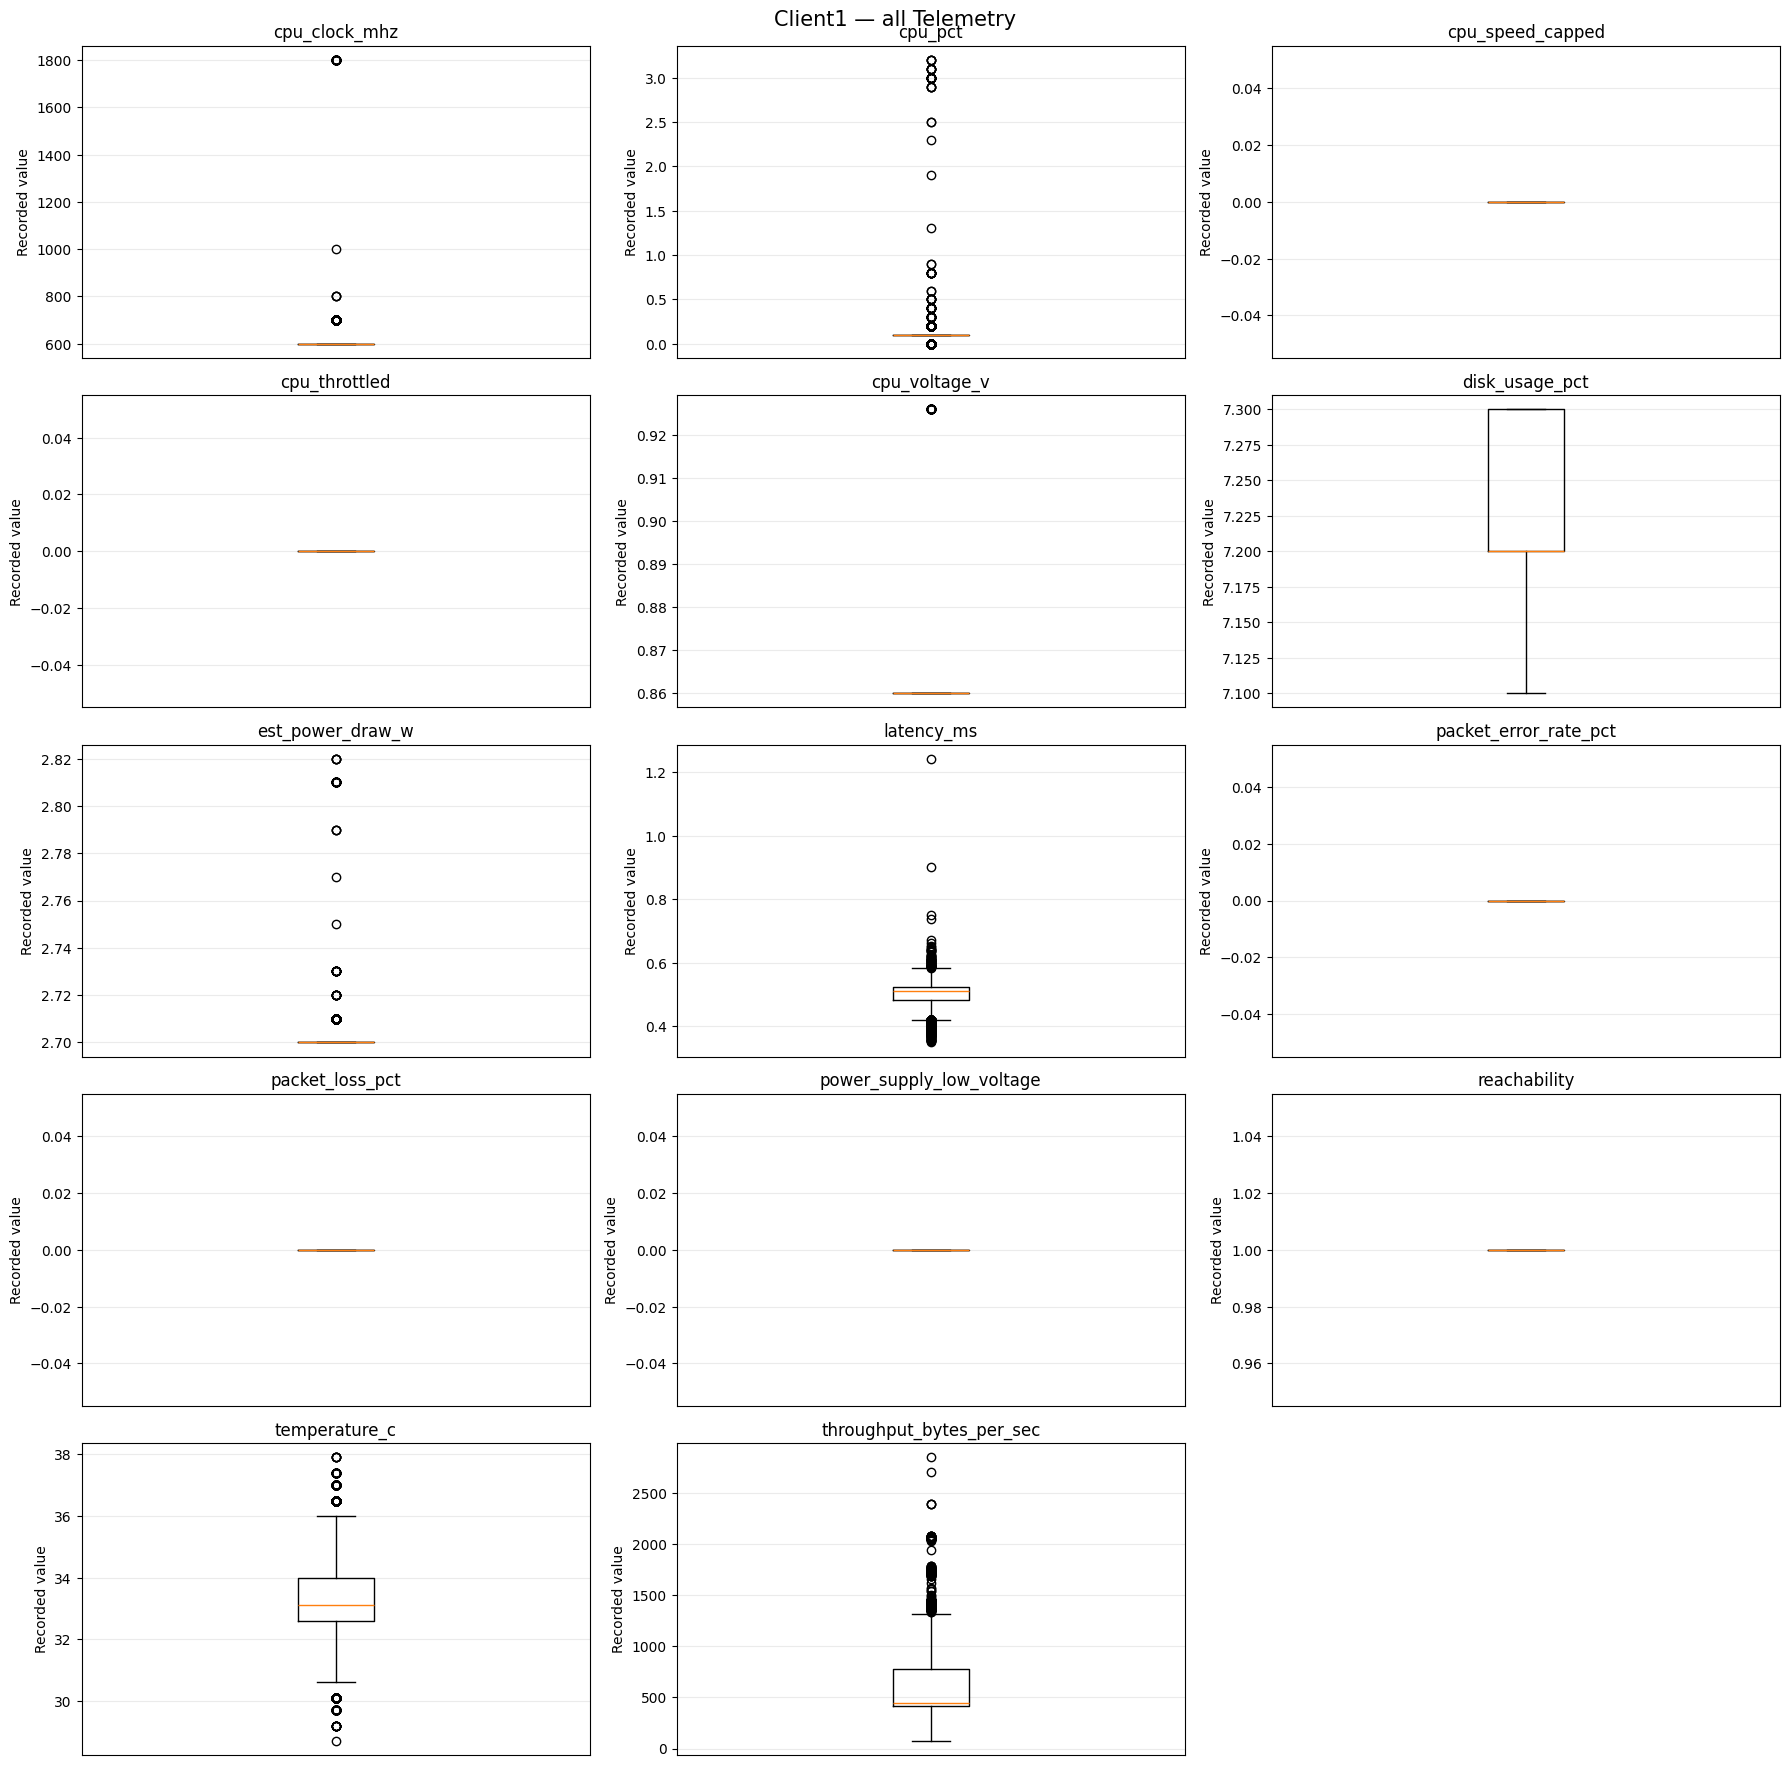

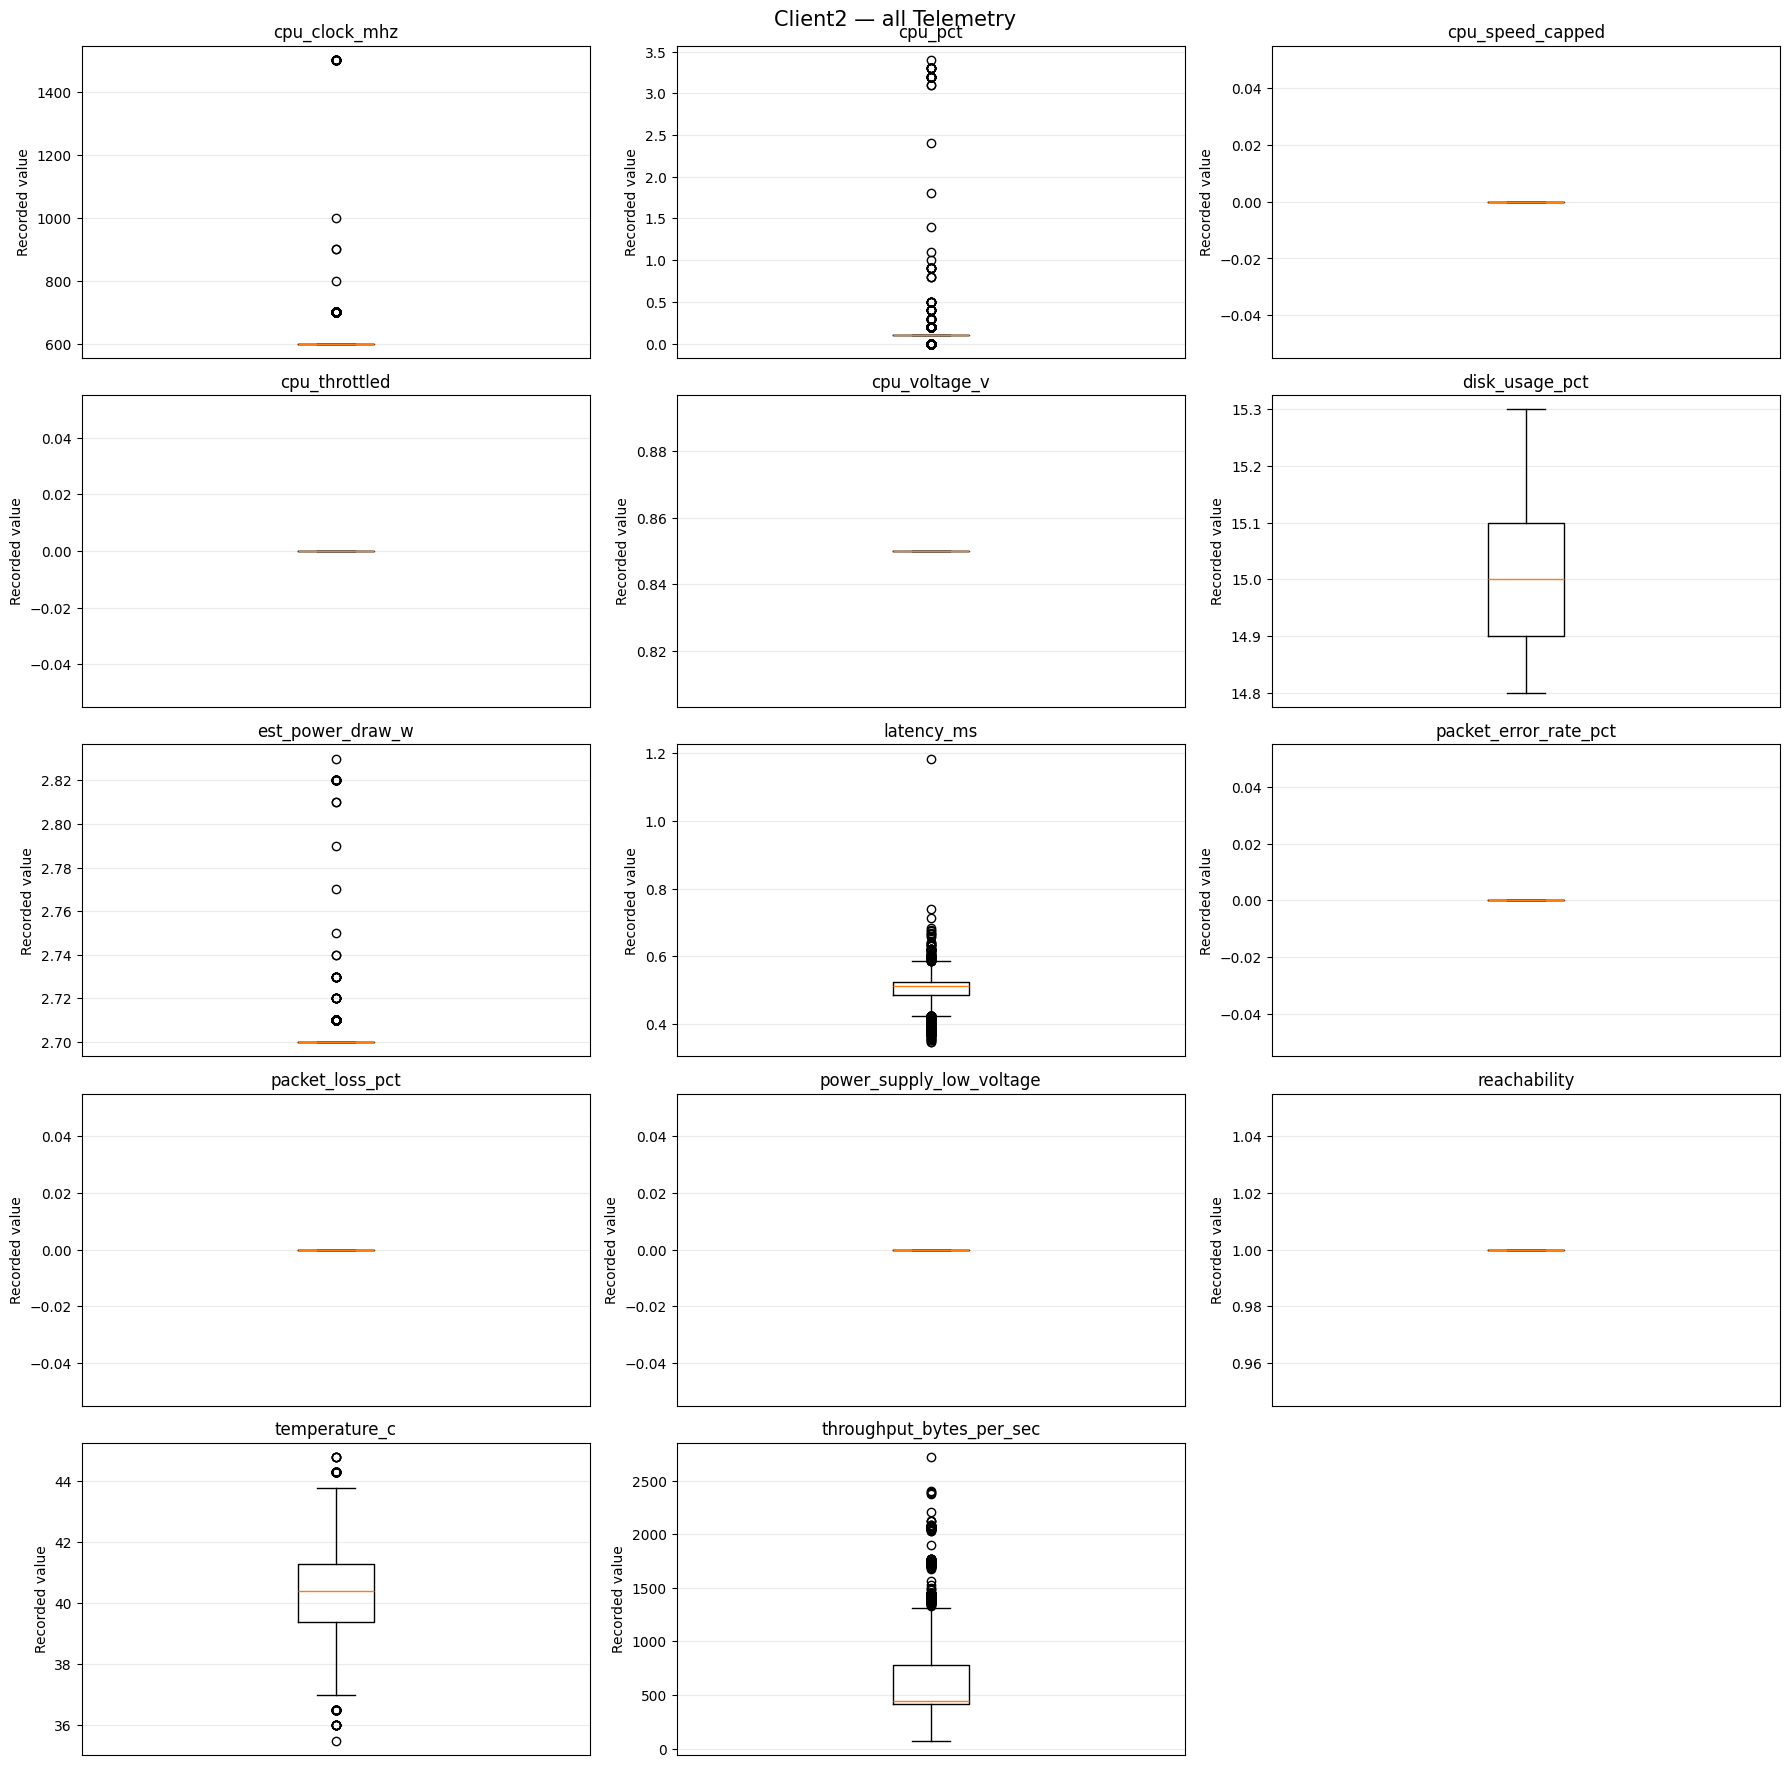

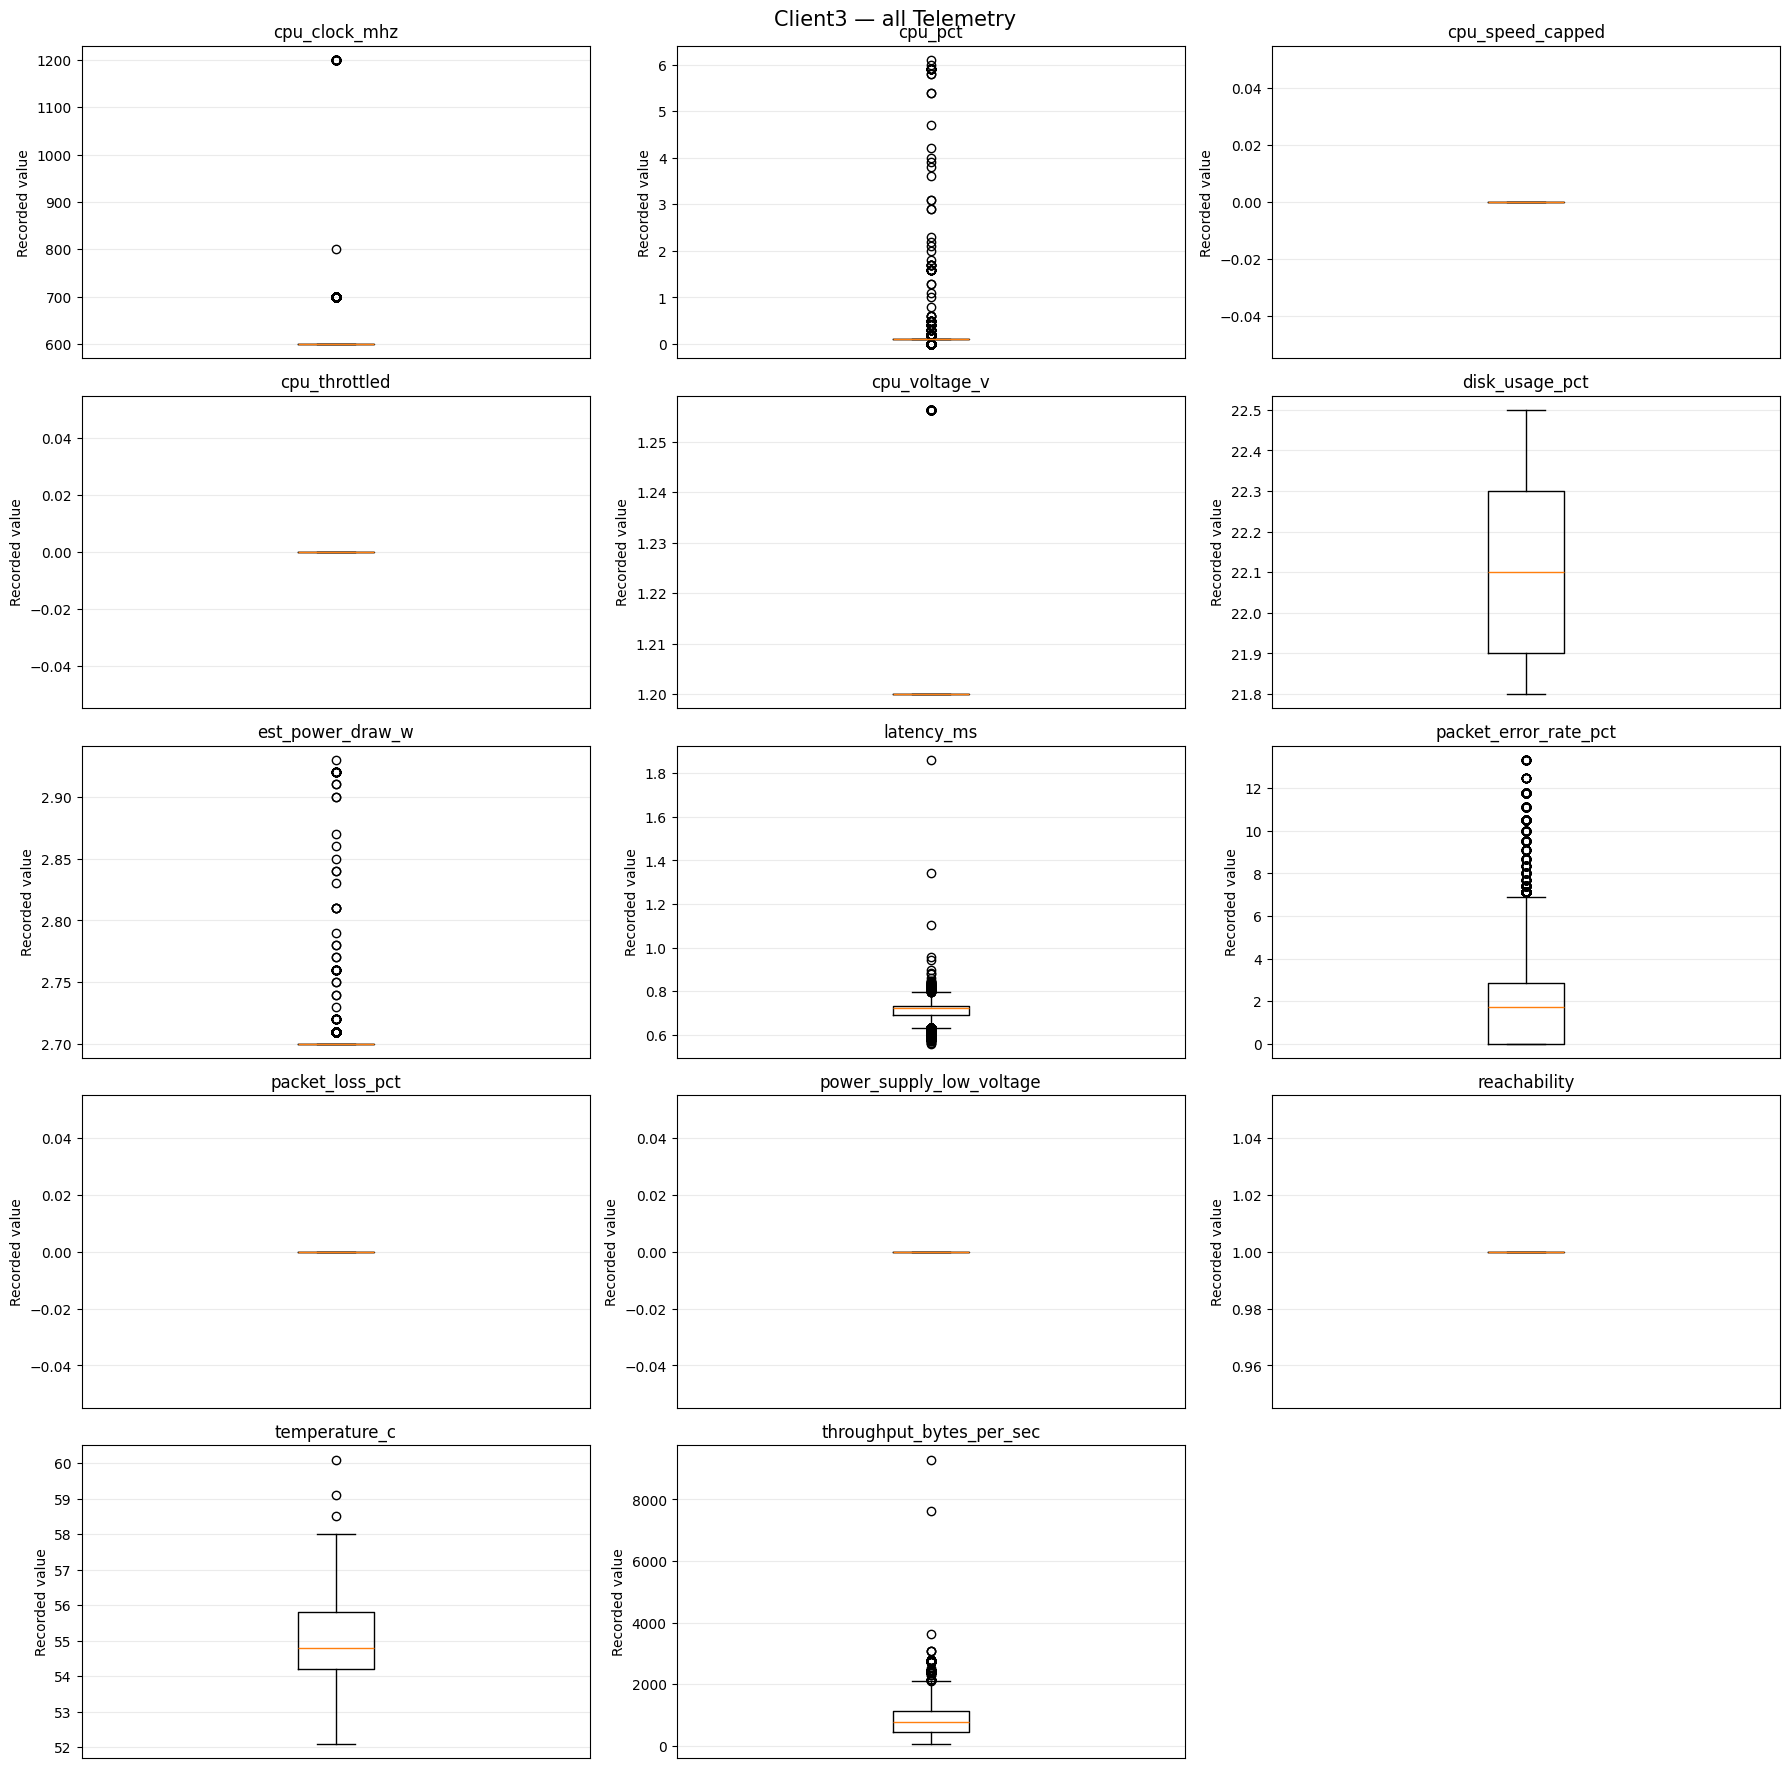

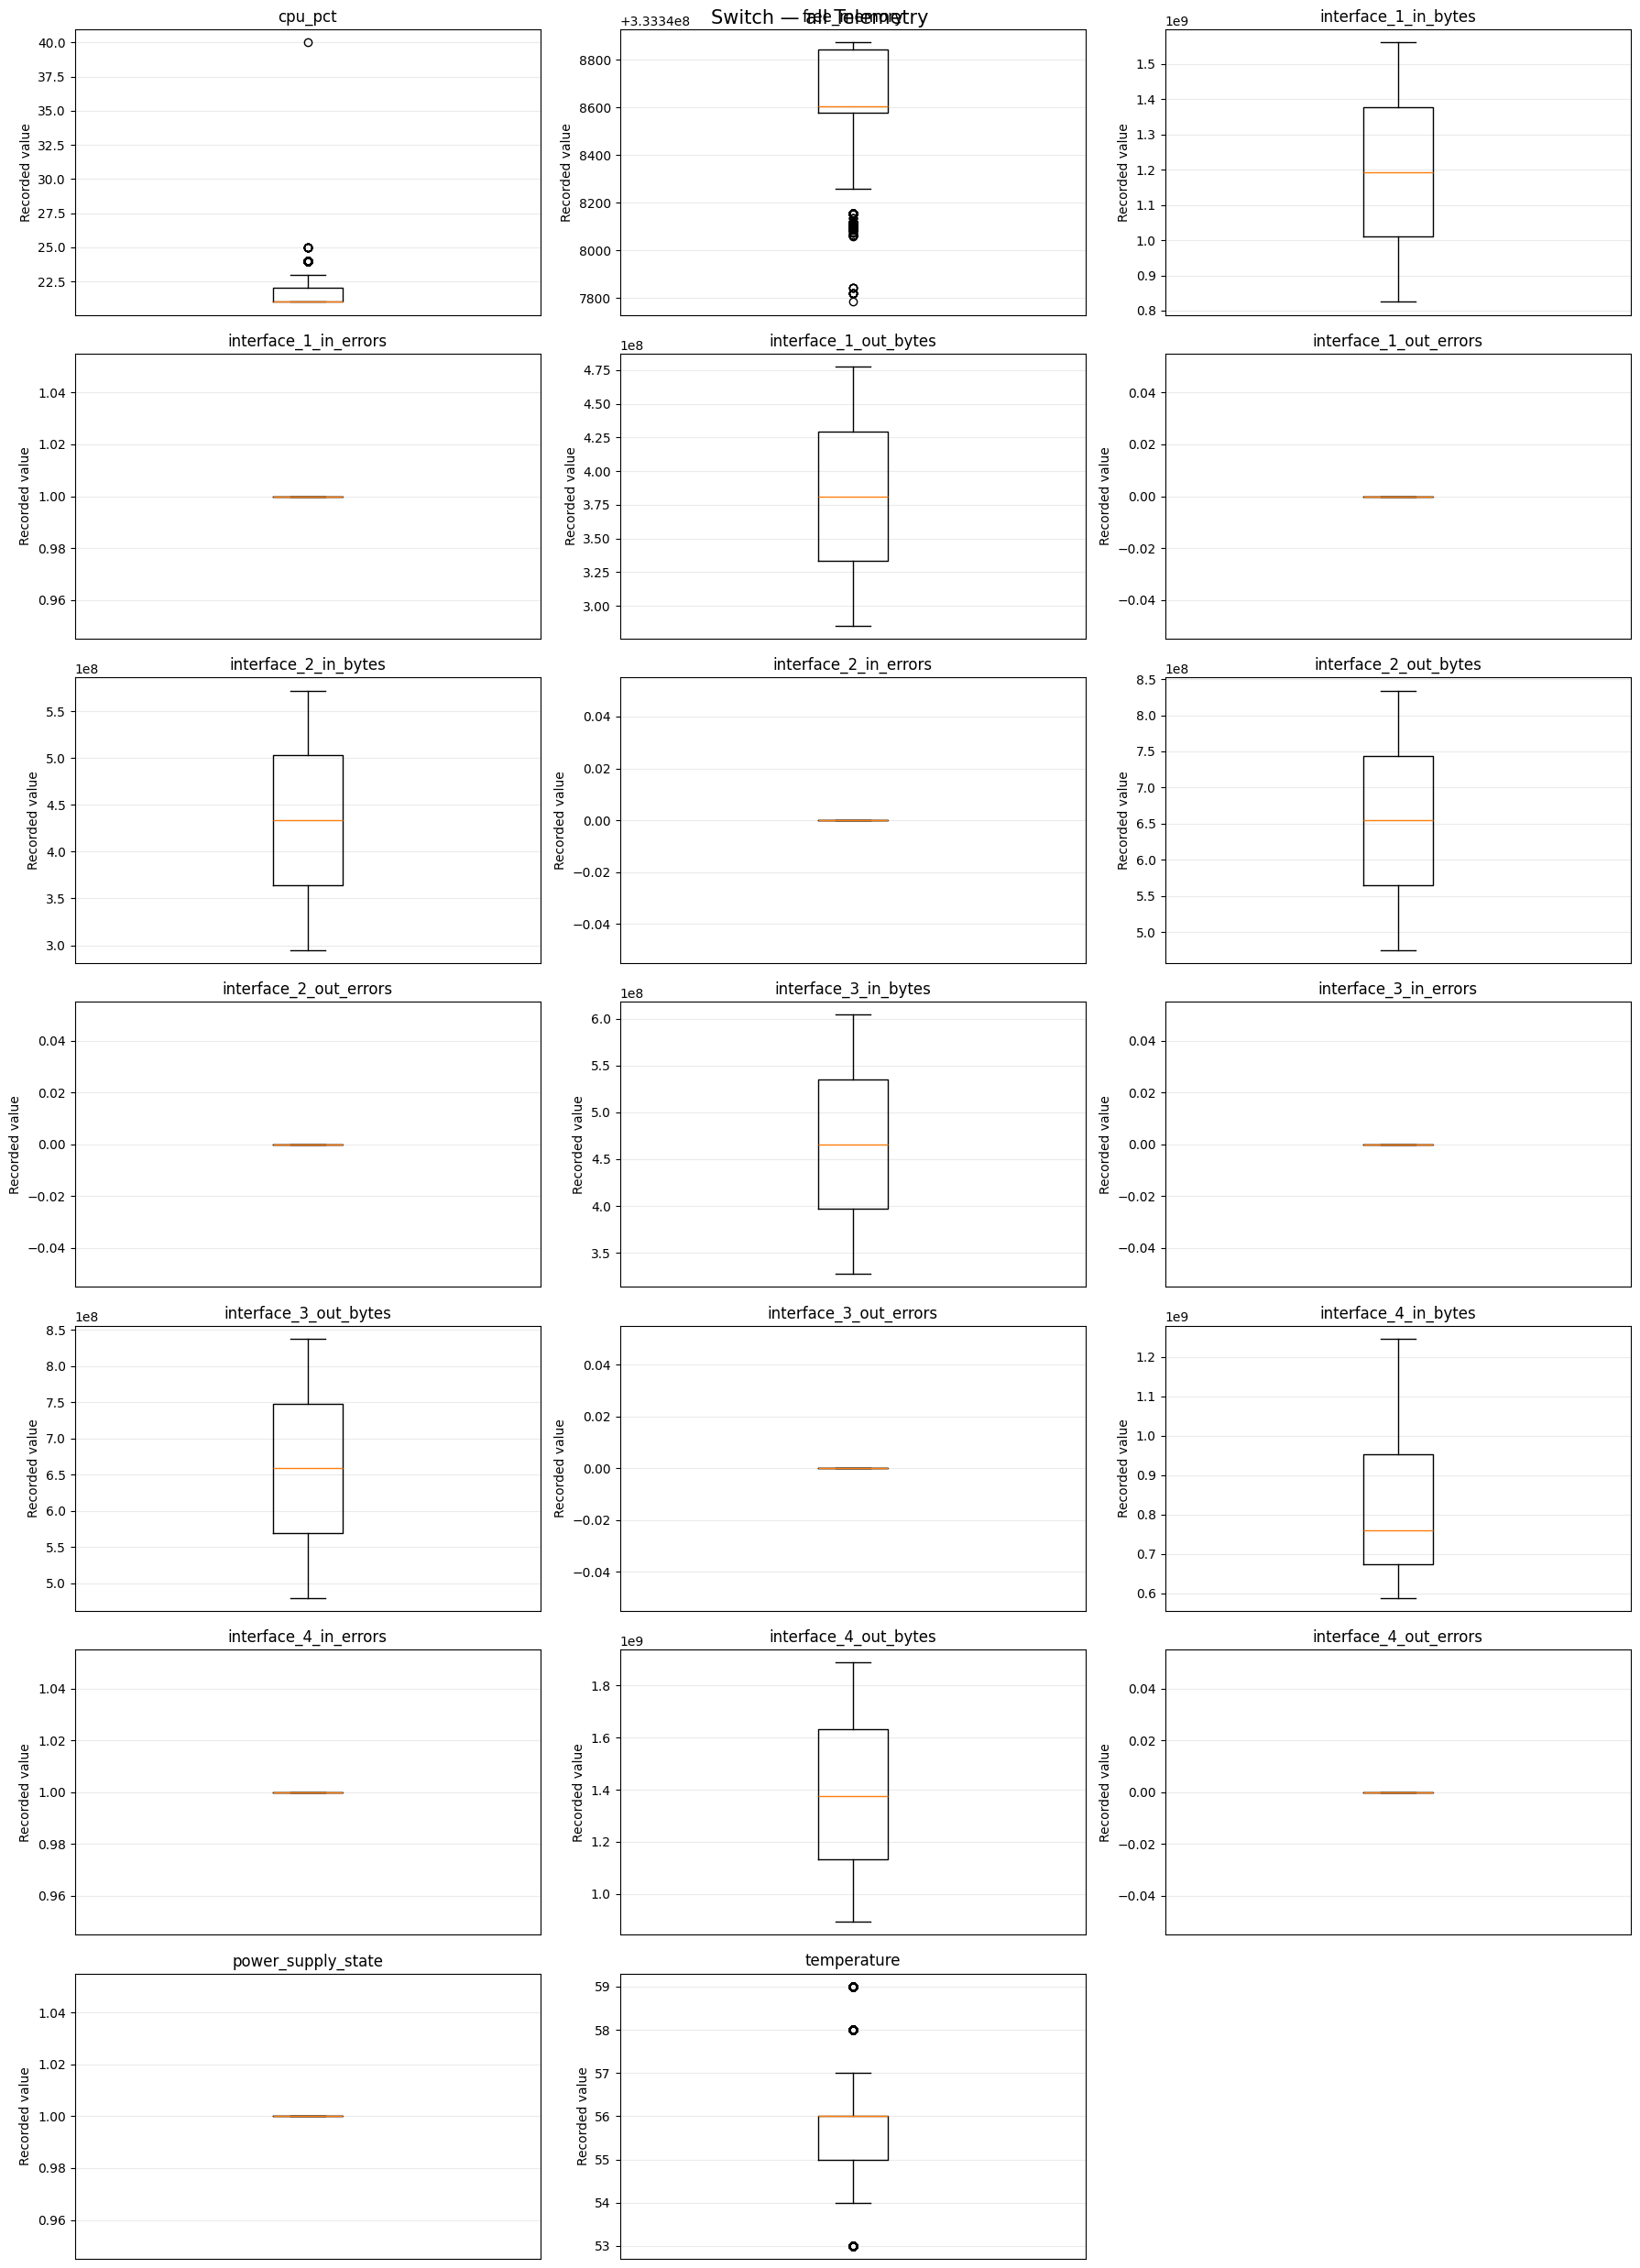


10.2 — Per-feature deviation box plots


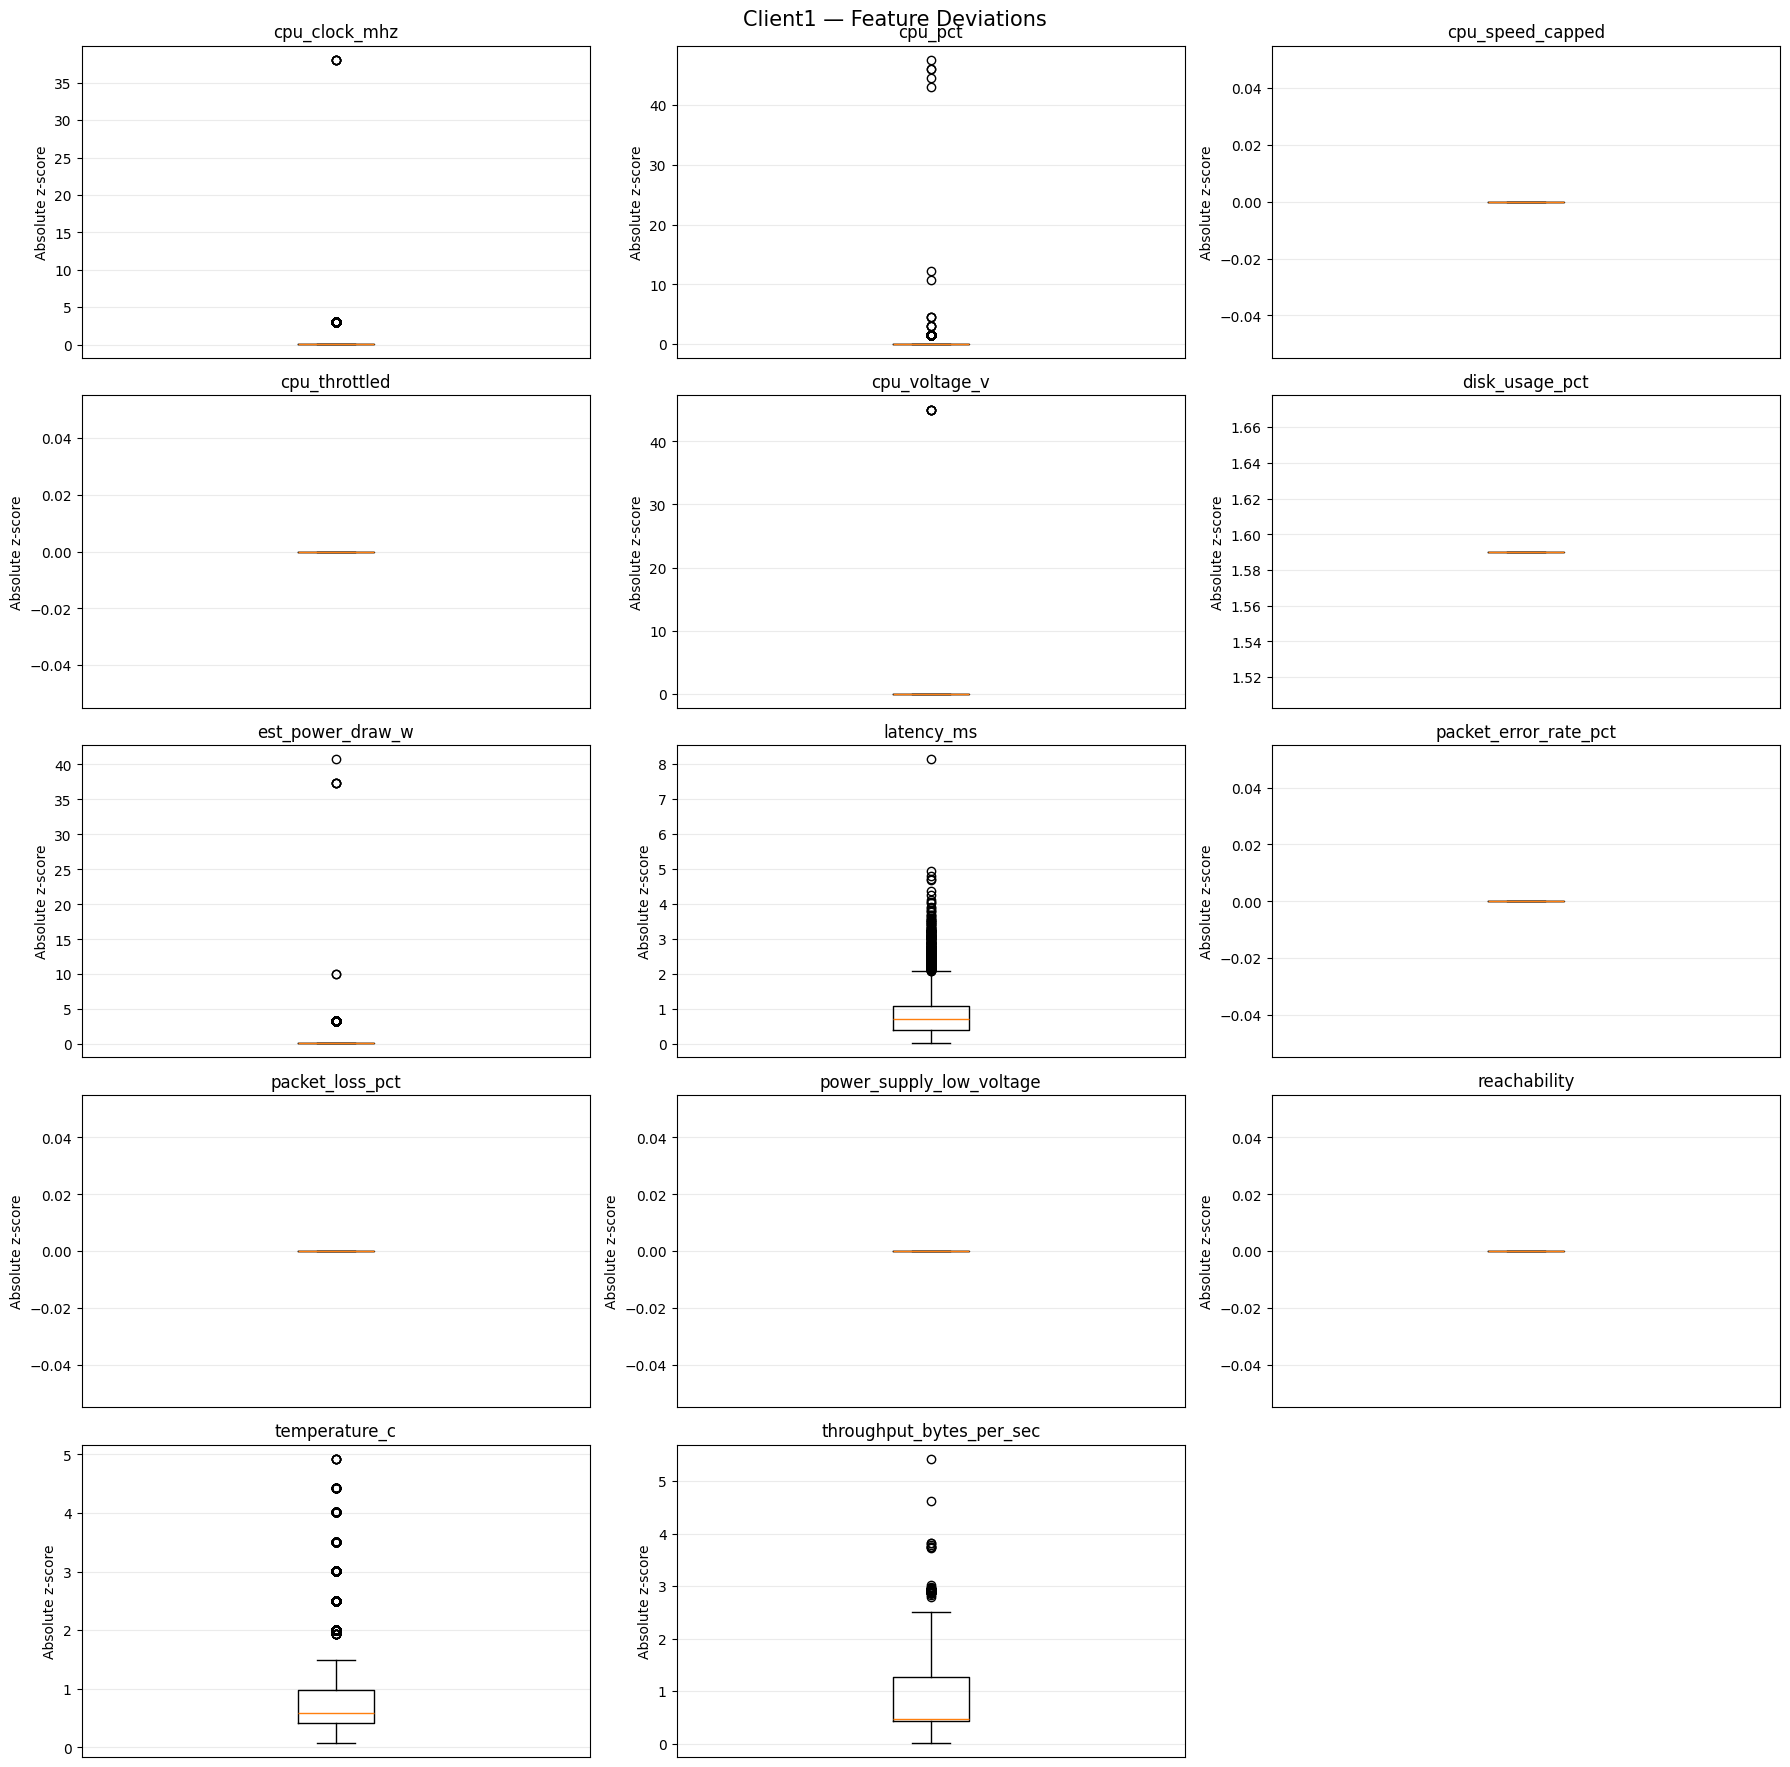

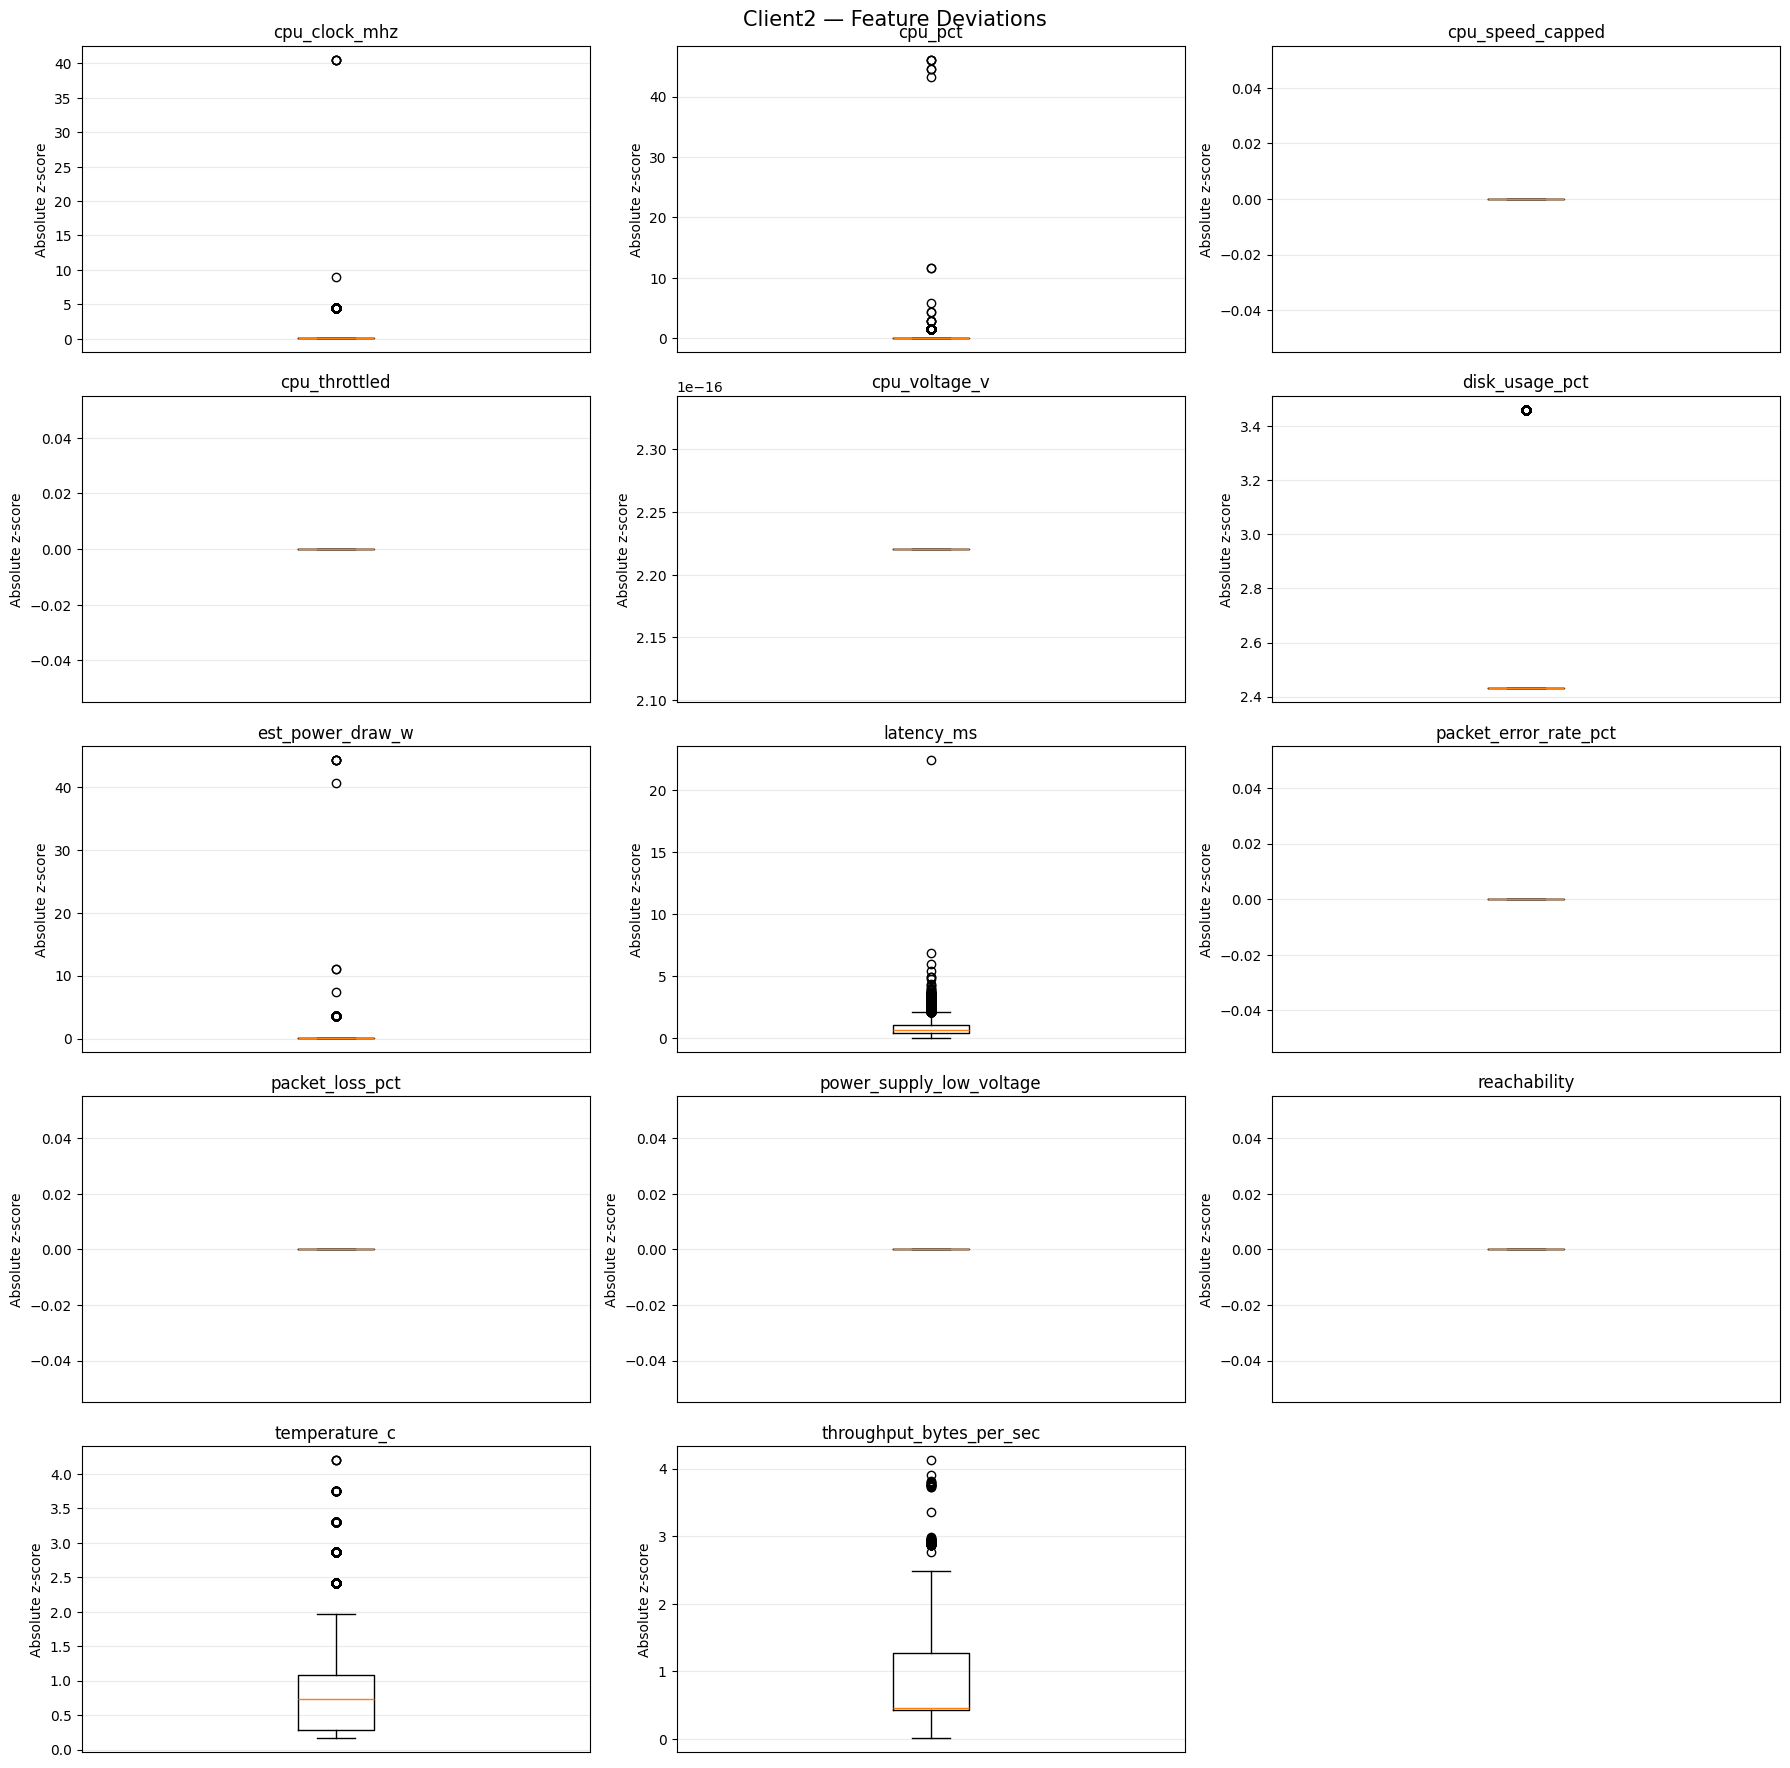

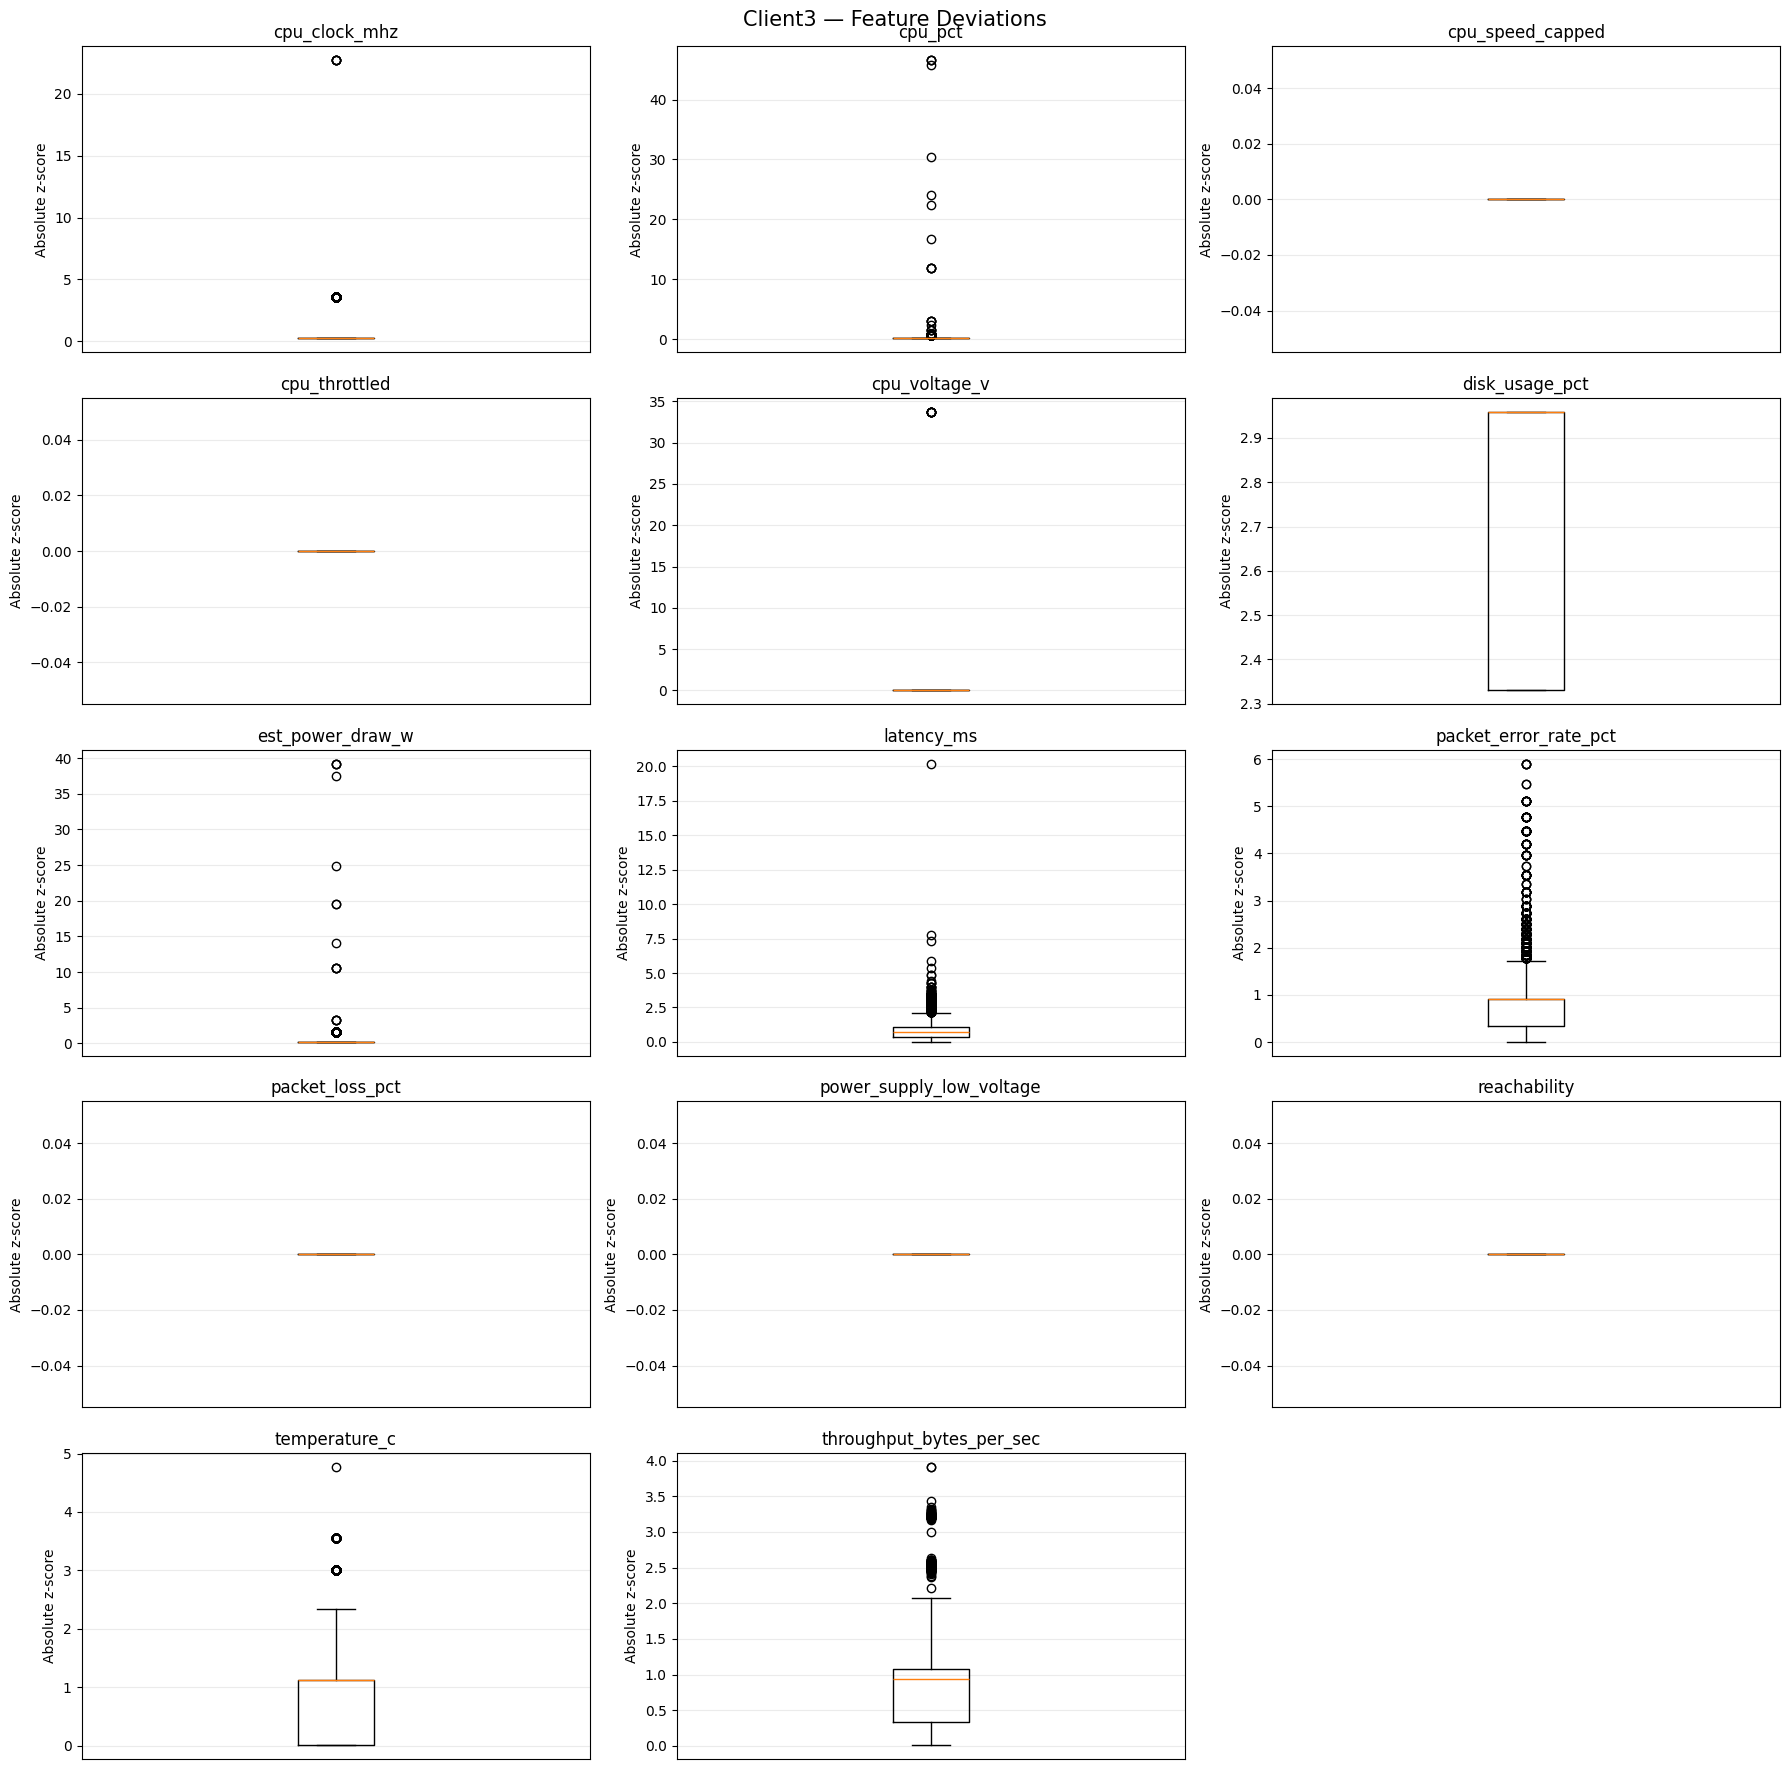

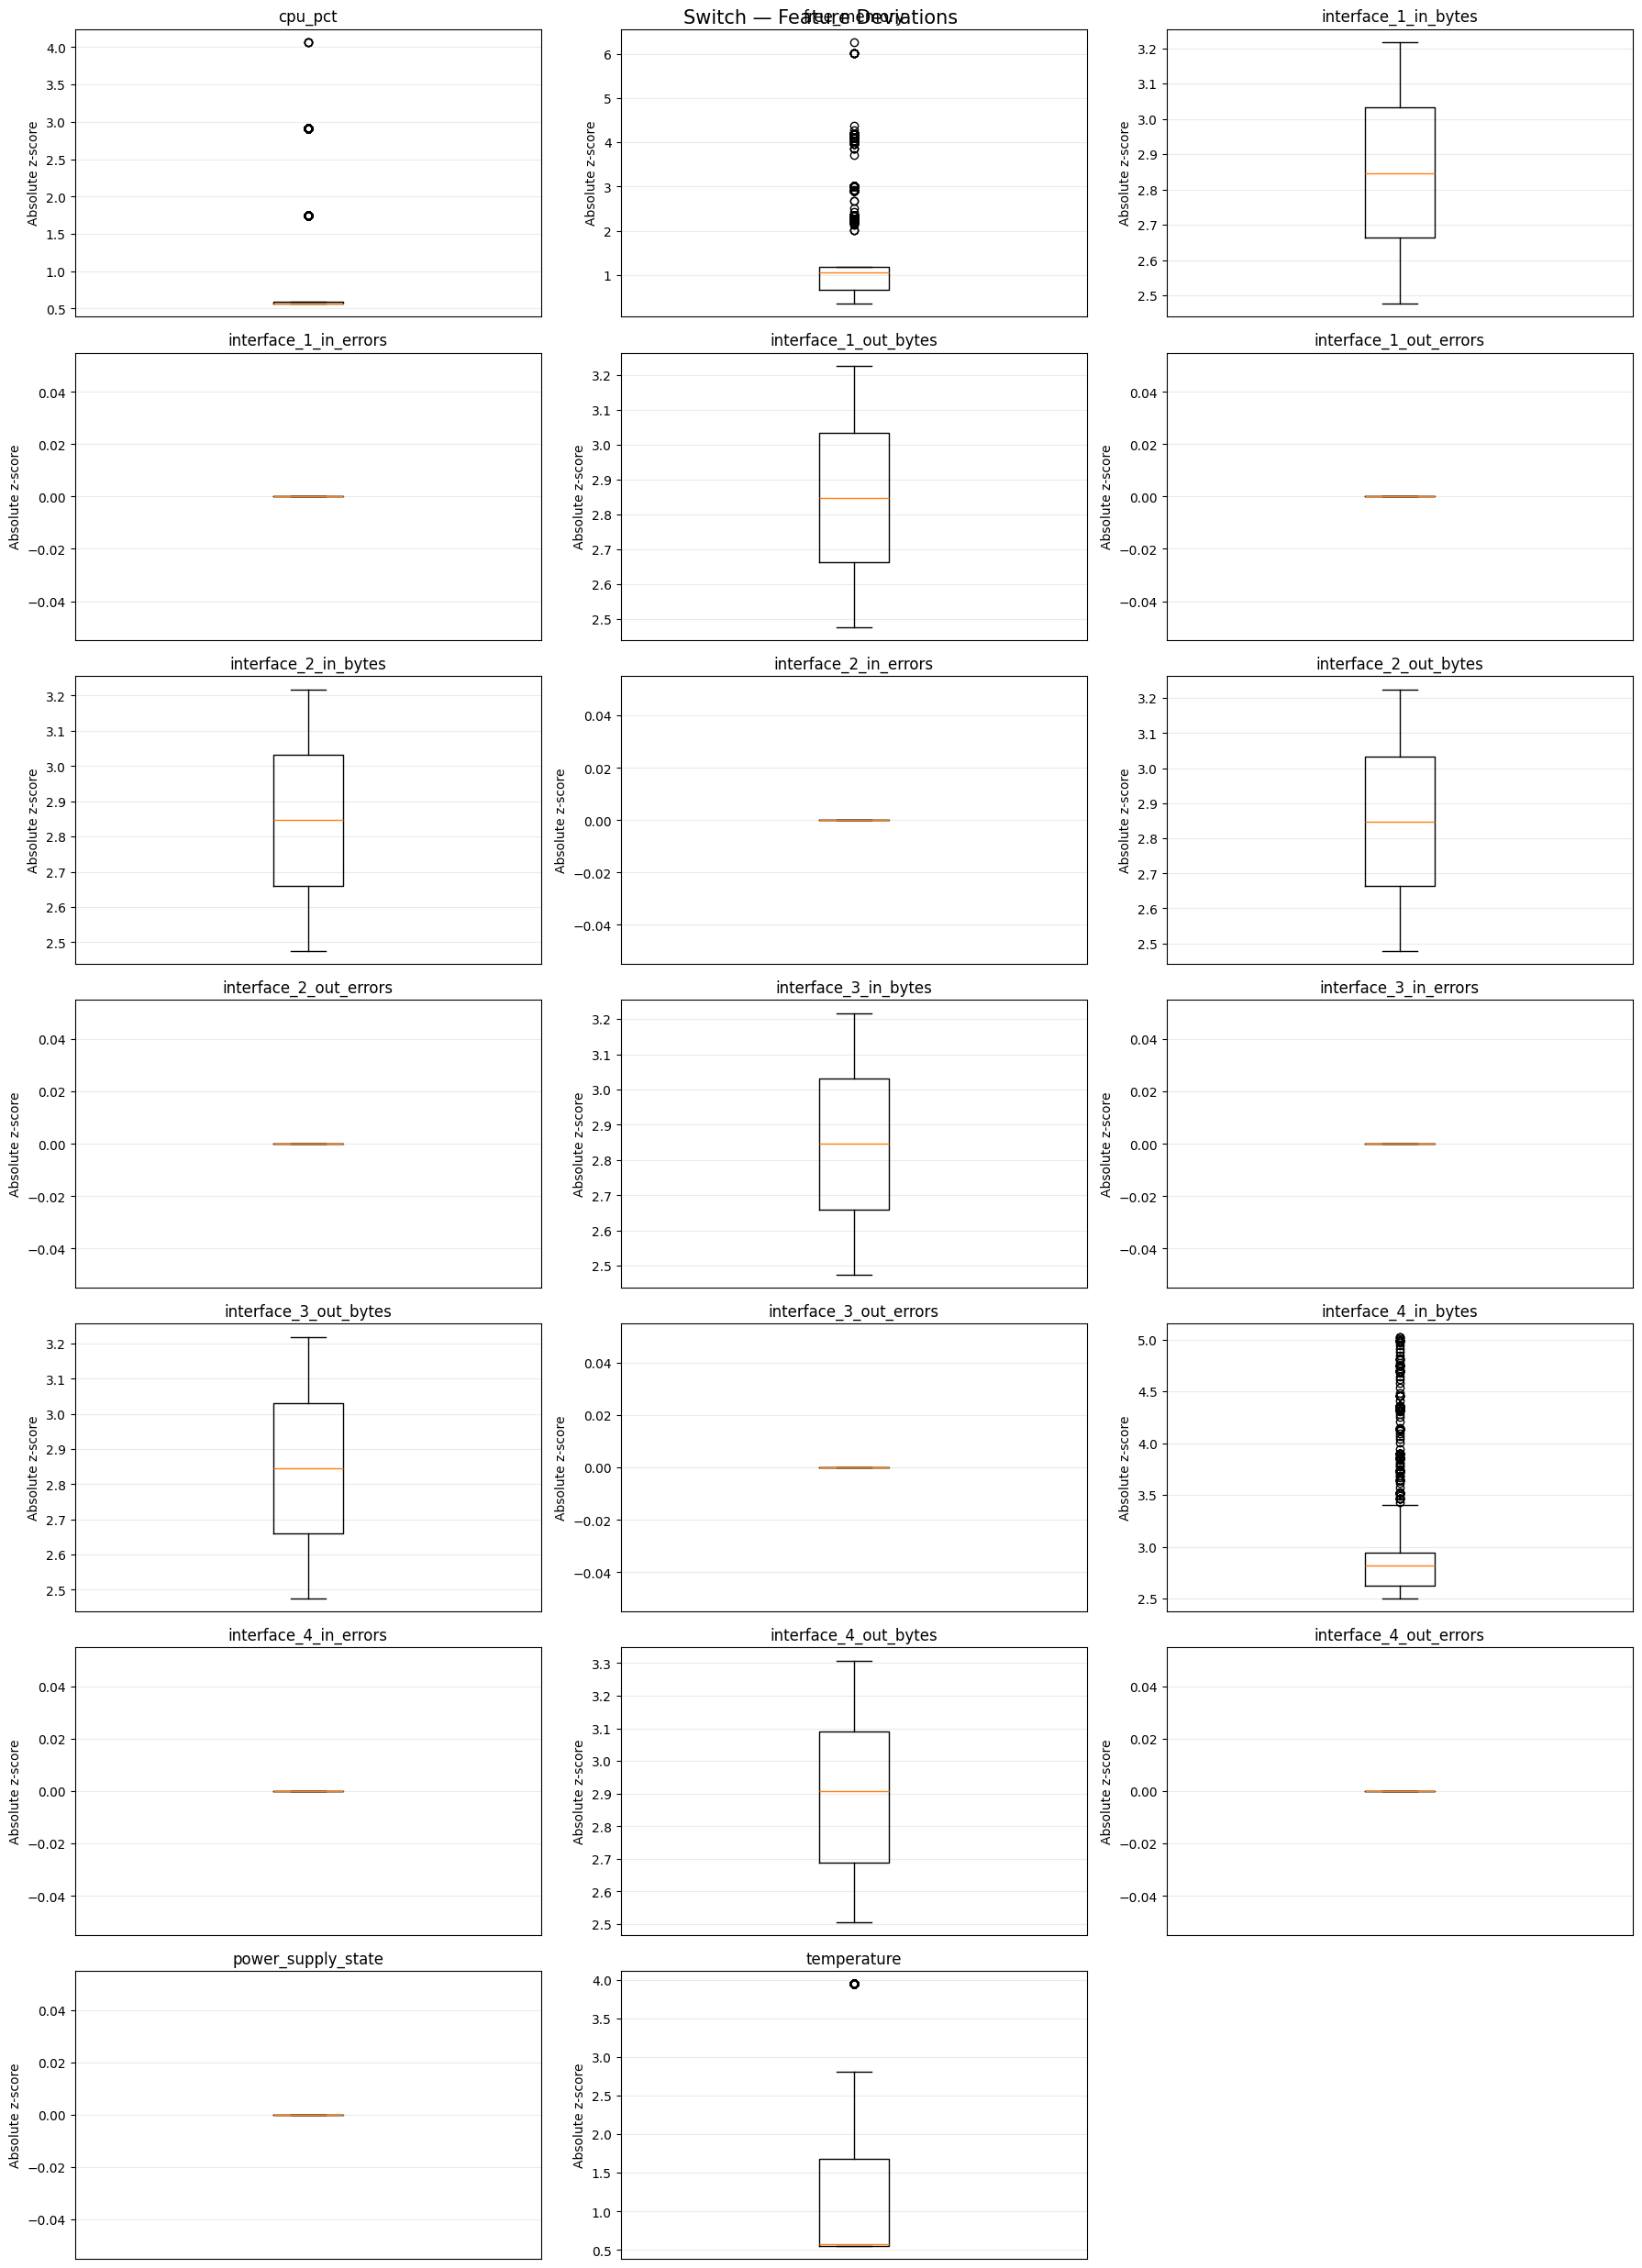


10.3 — Anomaly-score box plots


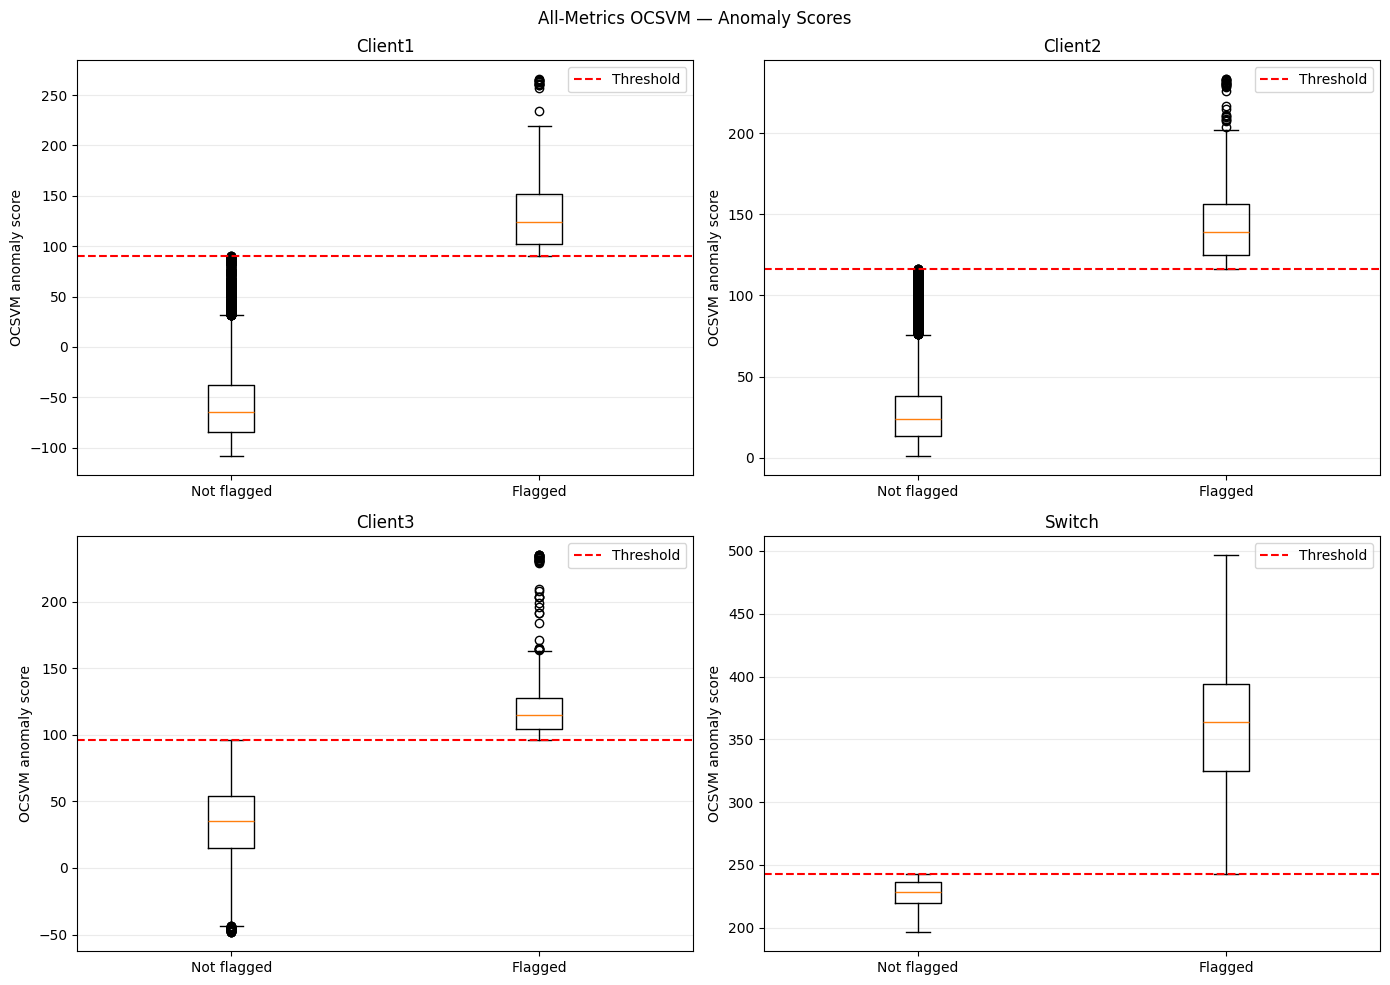


10.4 — Threshold-centred scores


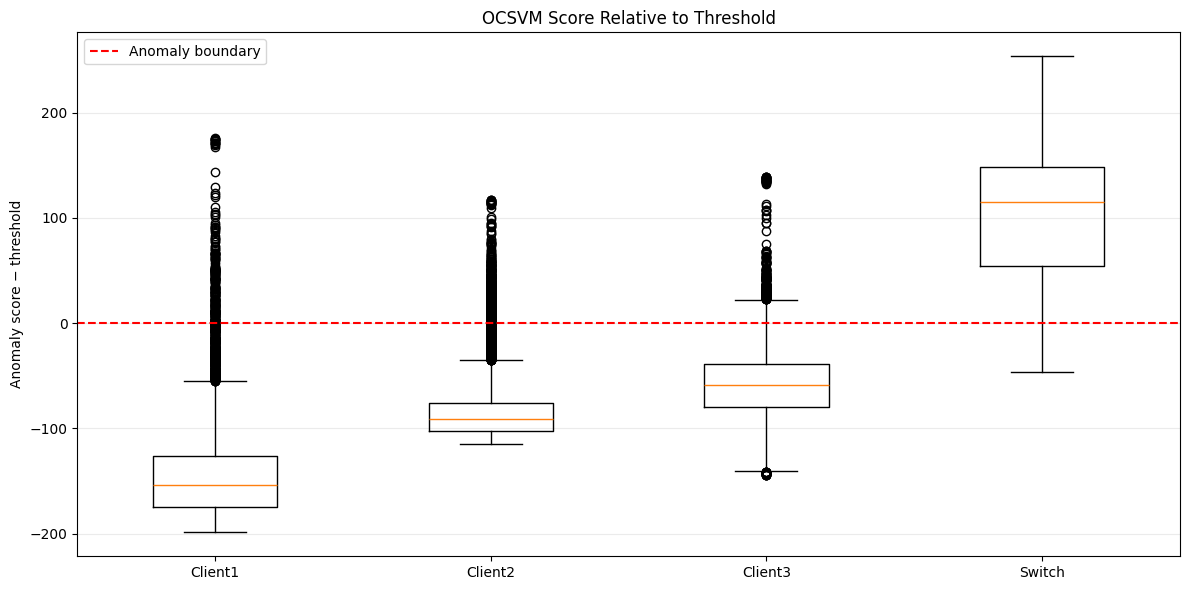


10.5 — Fault injection score box plots


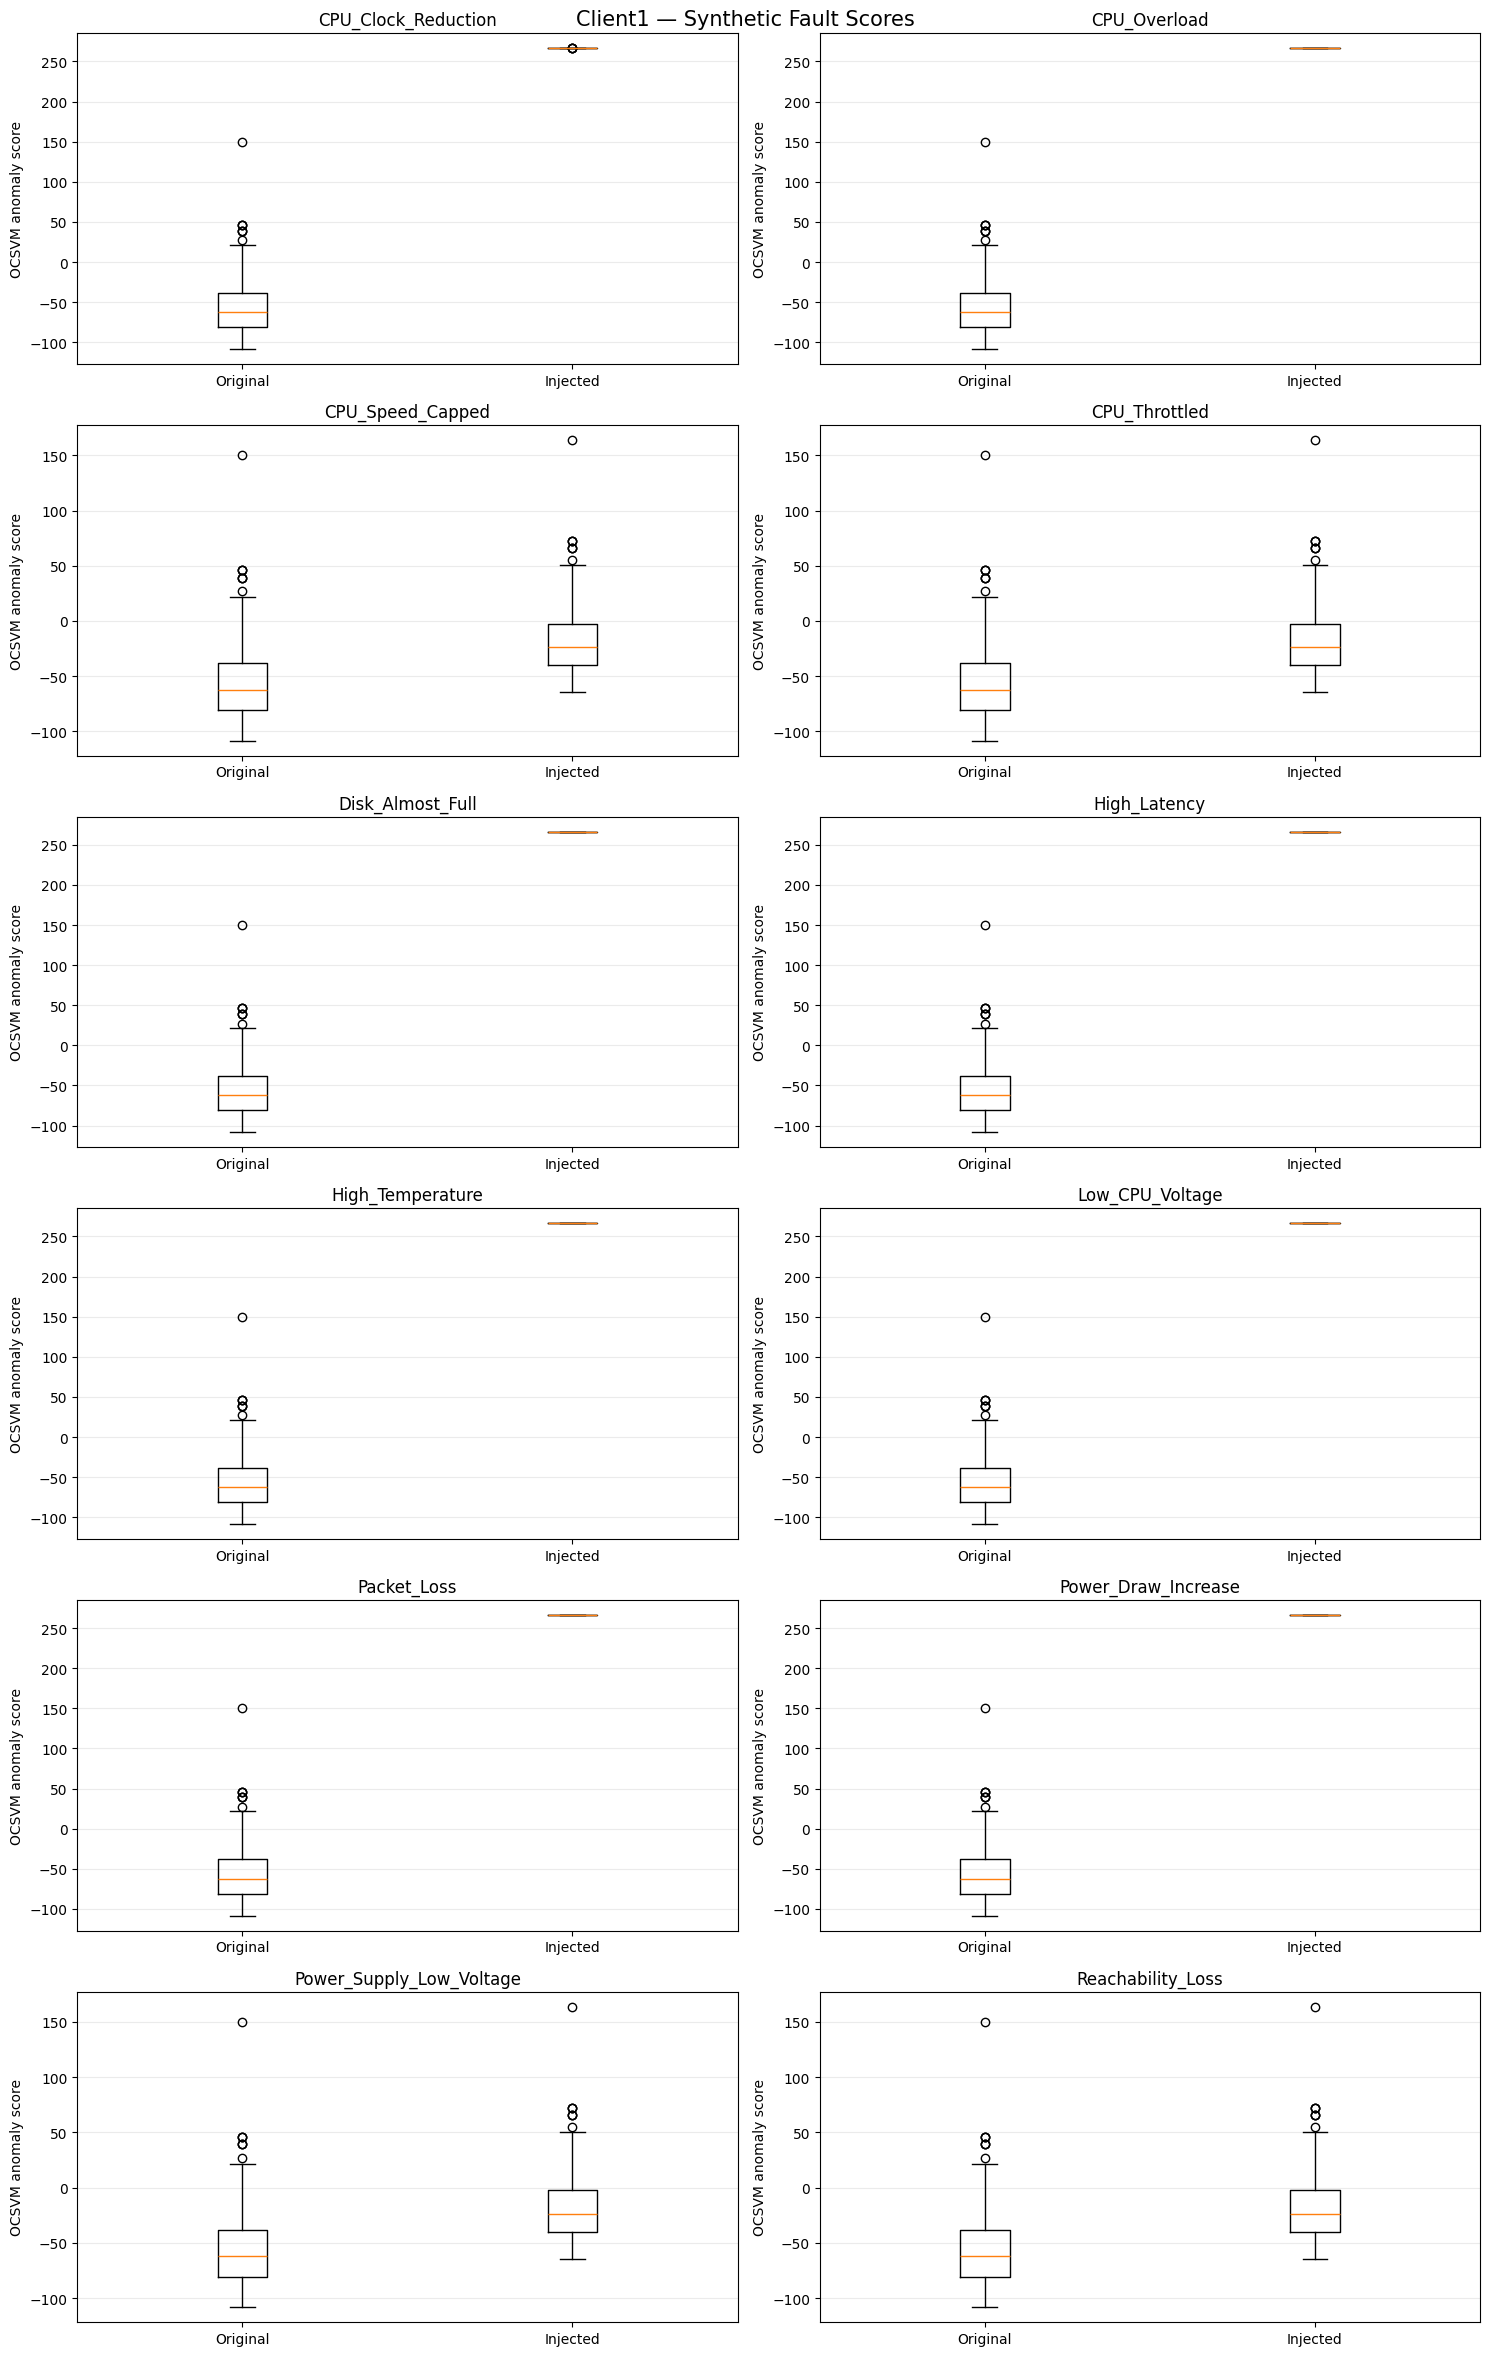

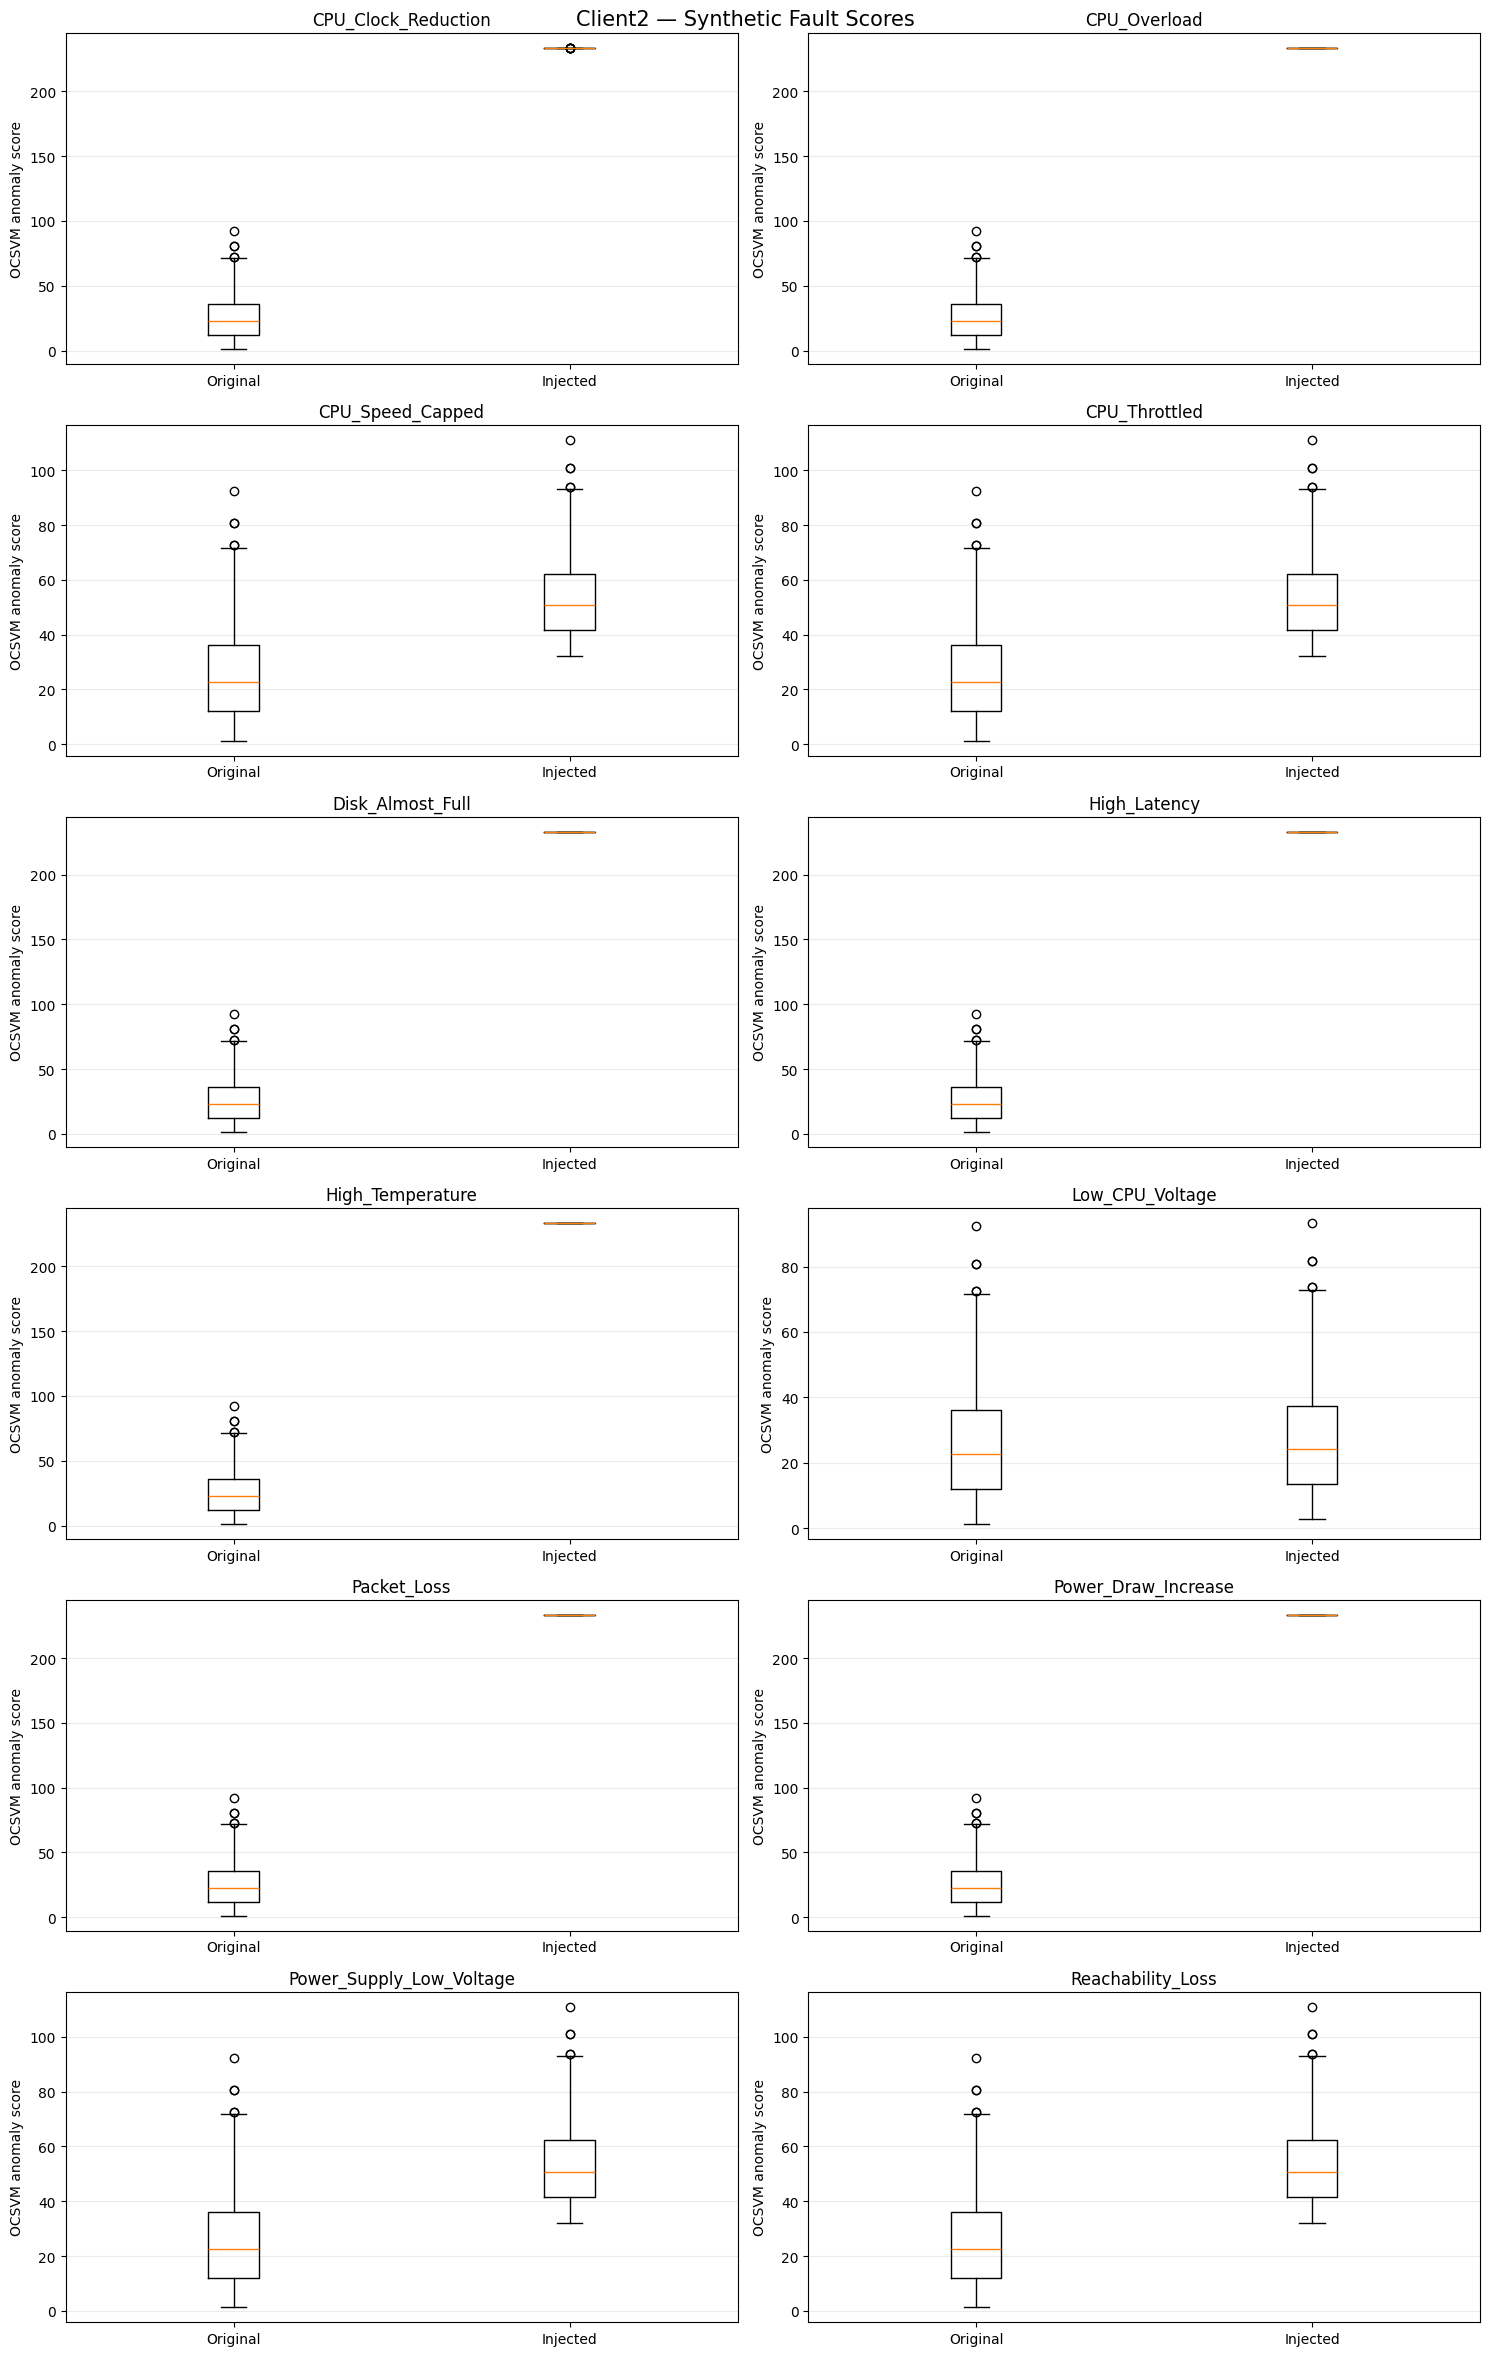

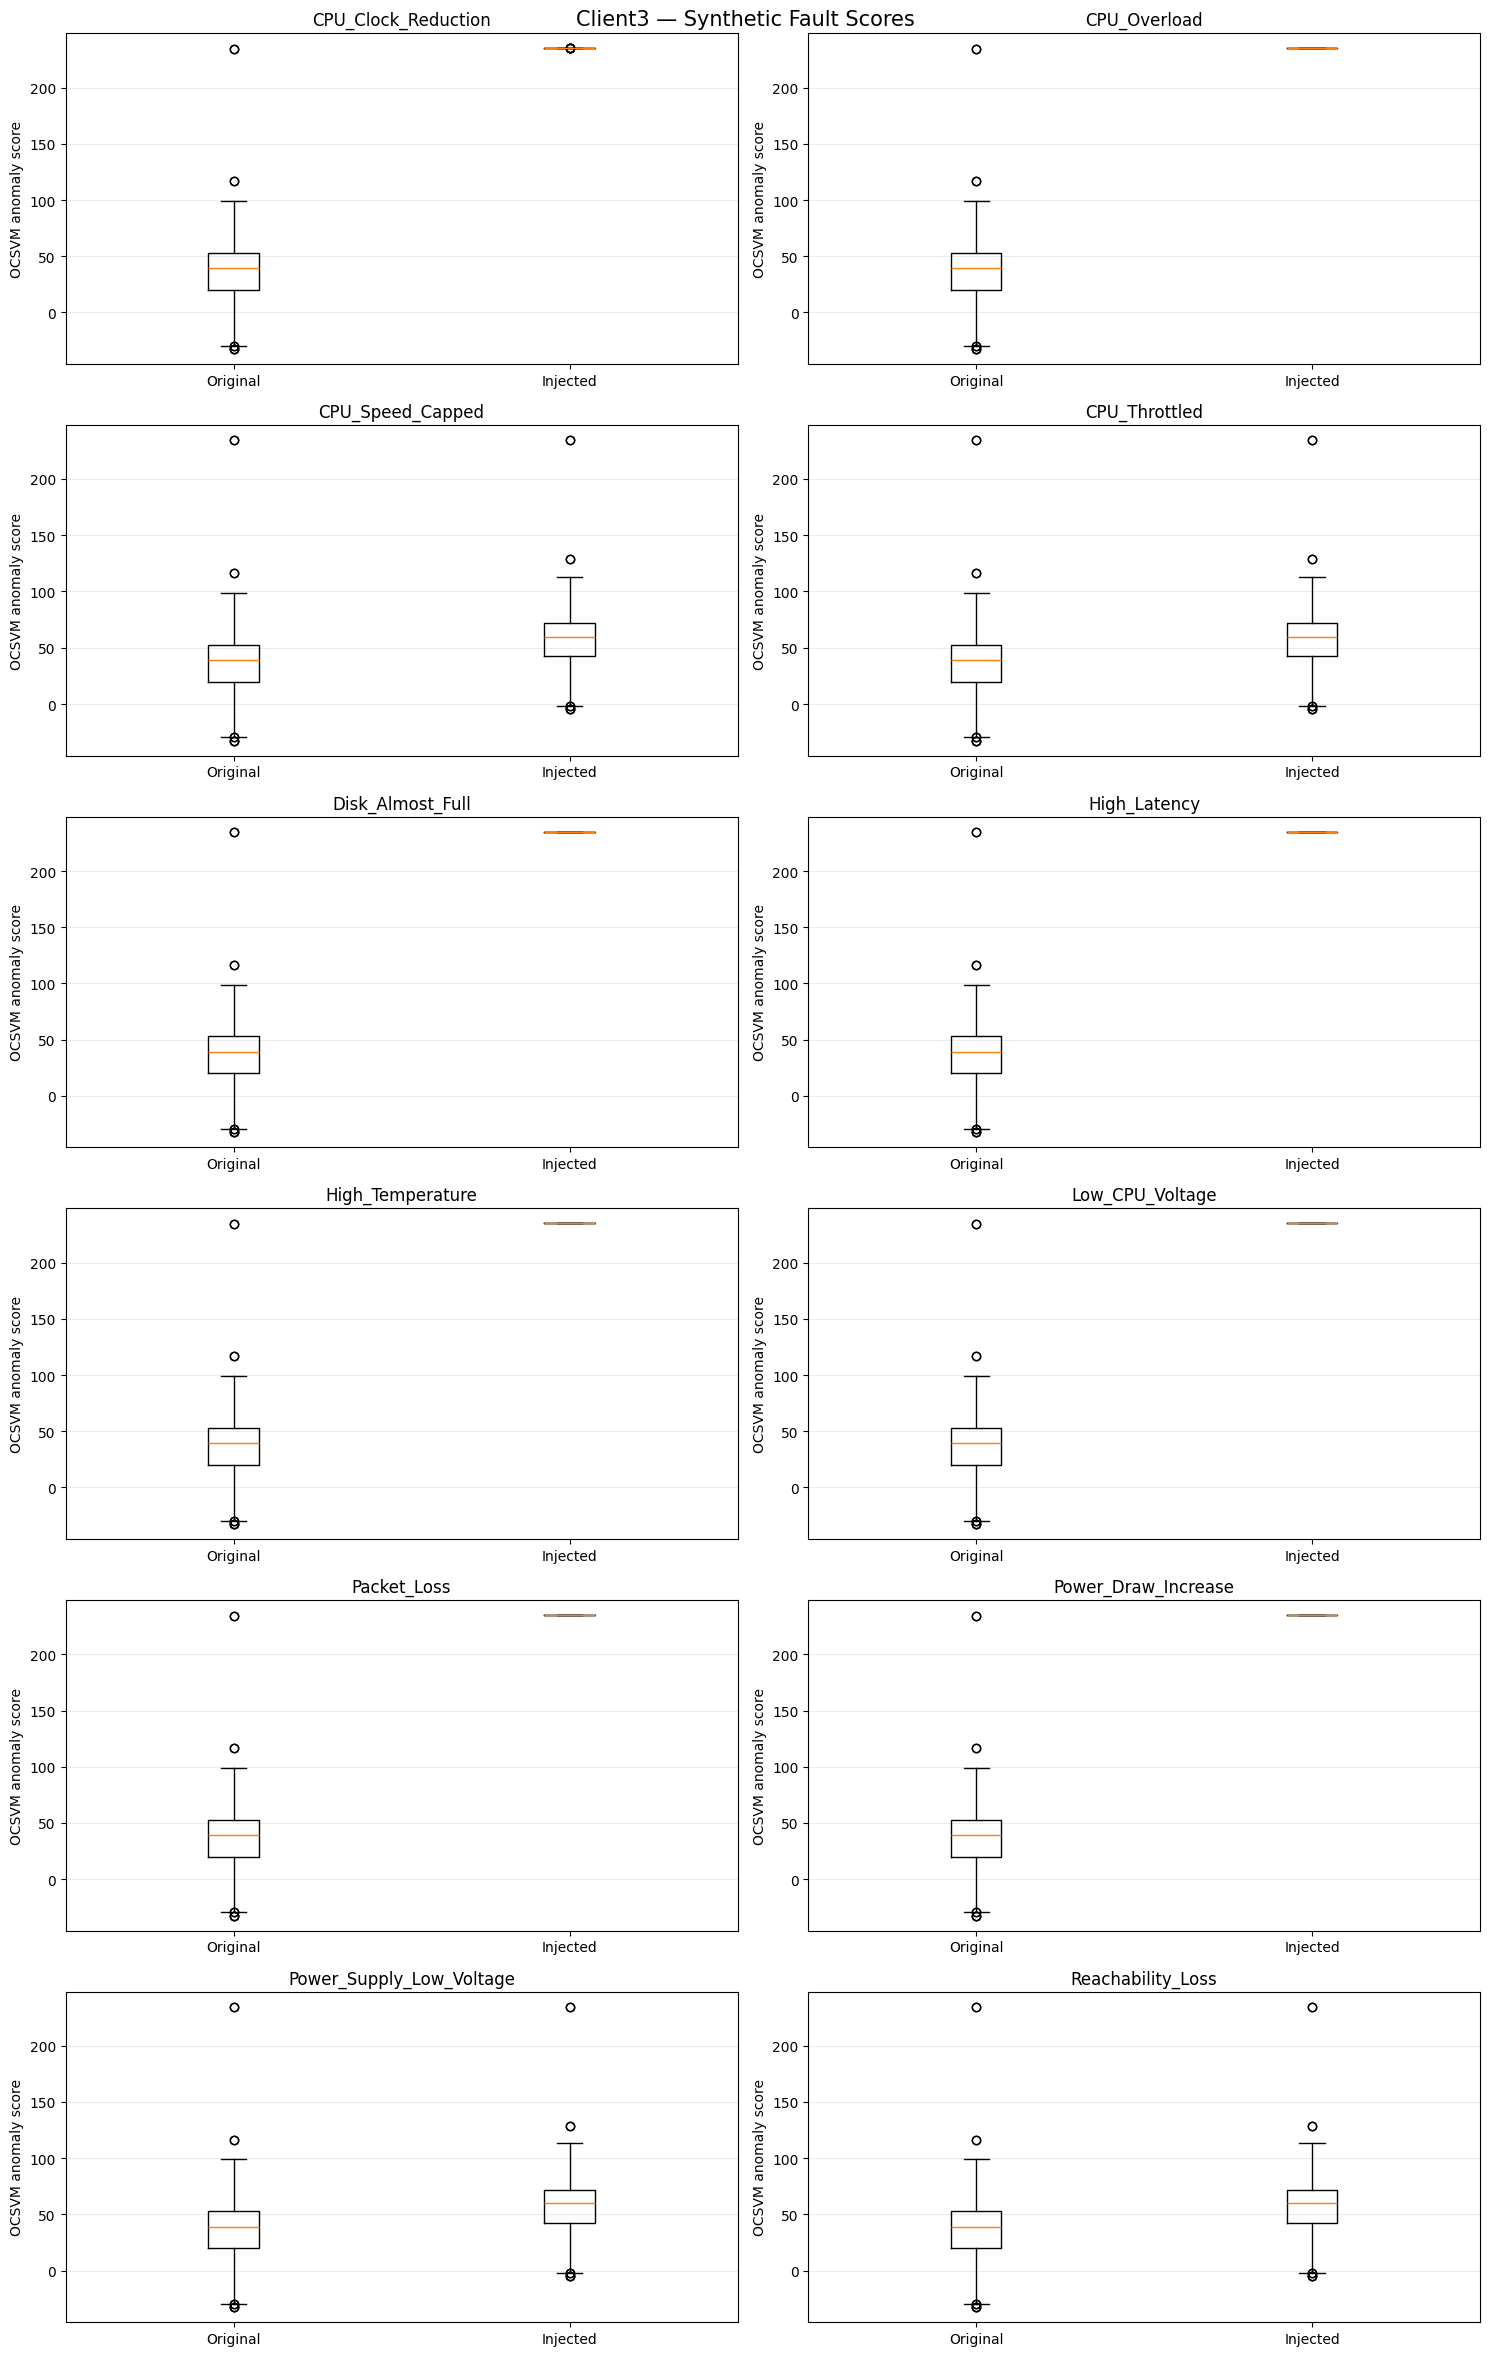

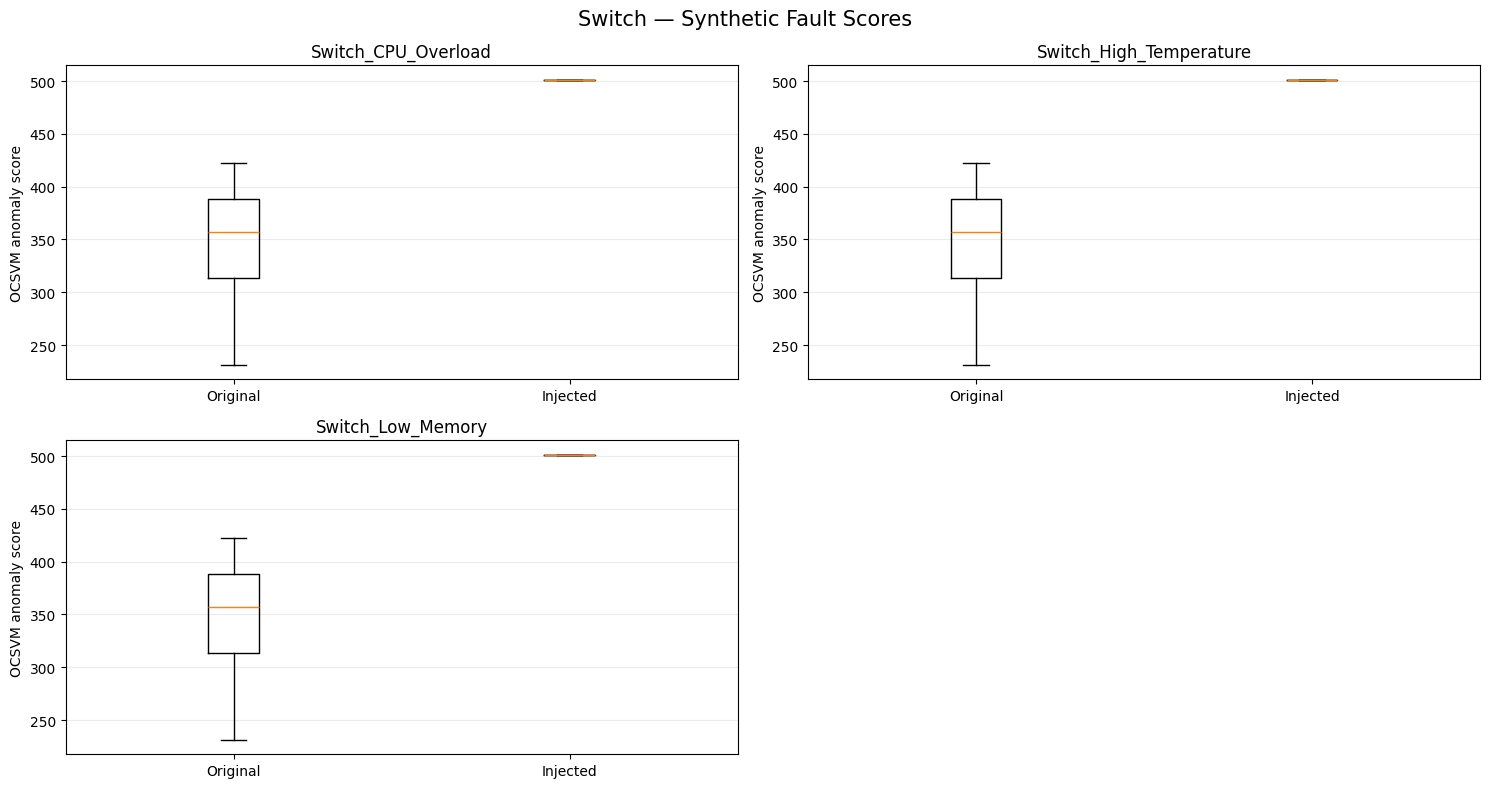


10.6 — Fault detection rates


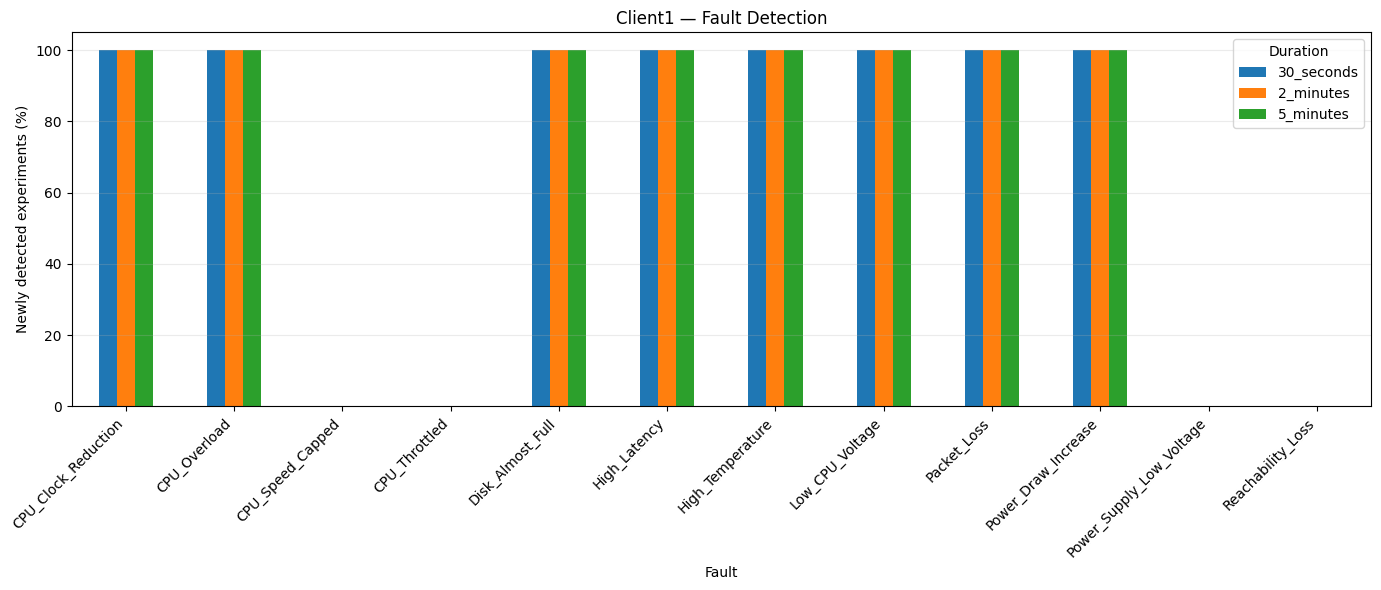

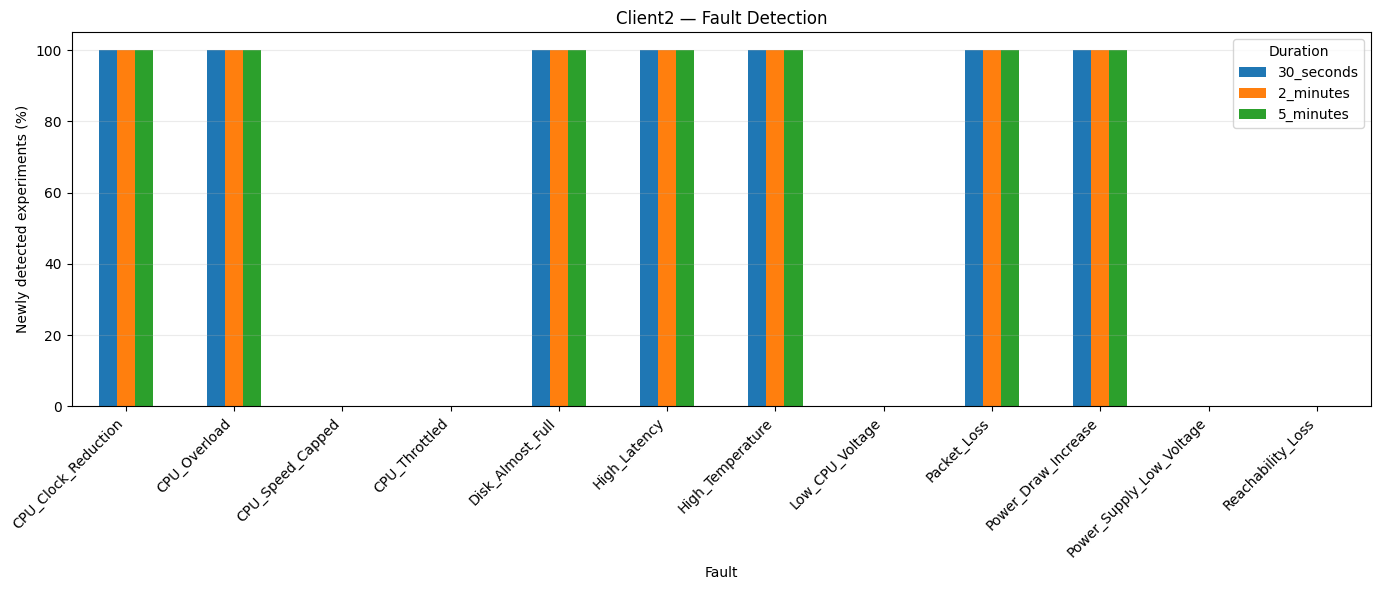

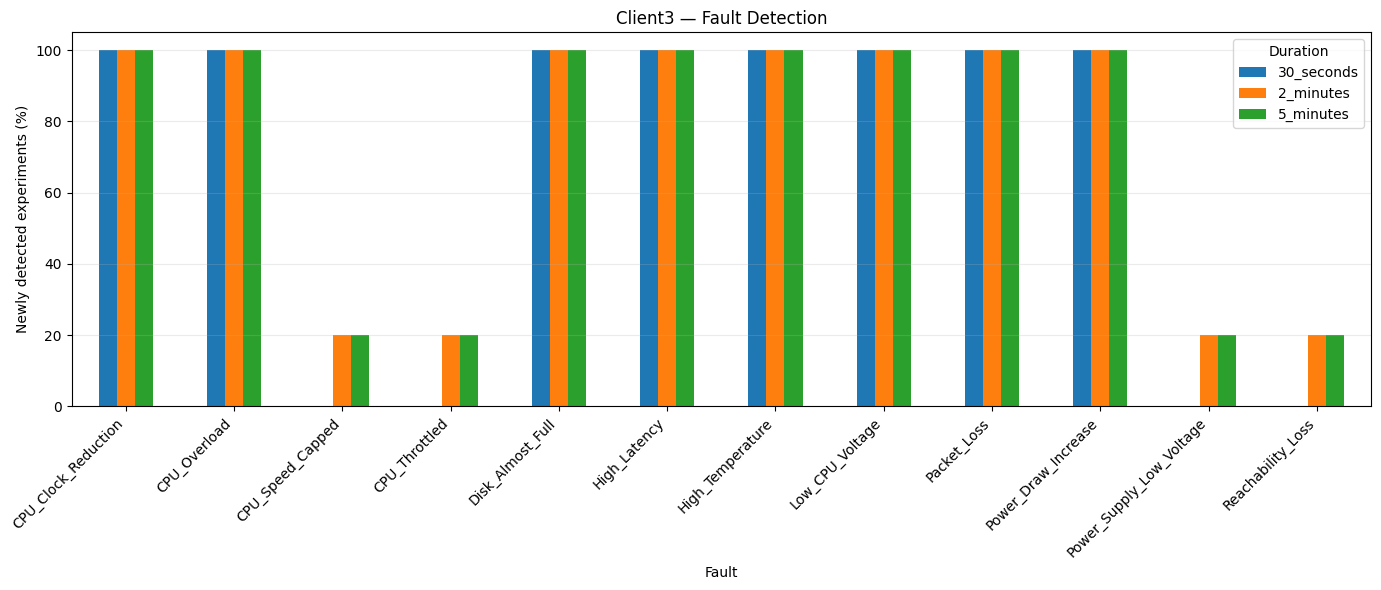

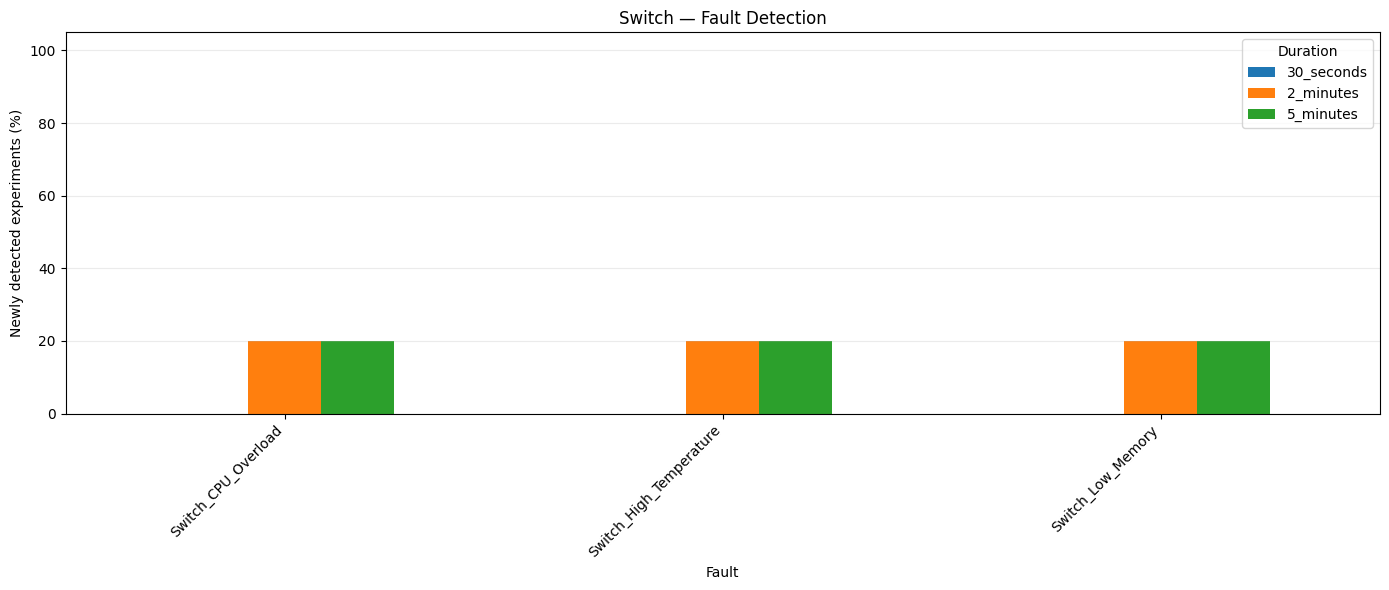


10.7 — Detection delay


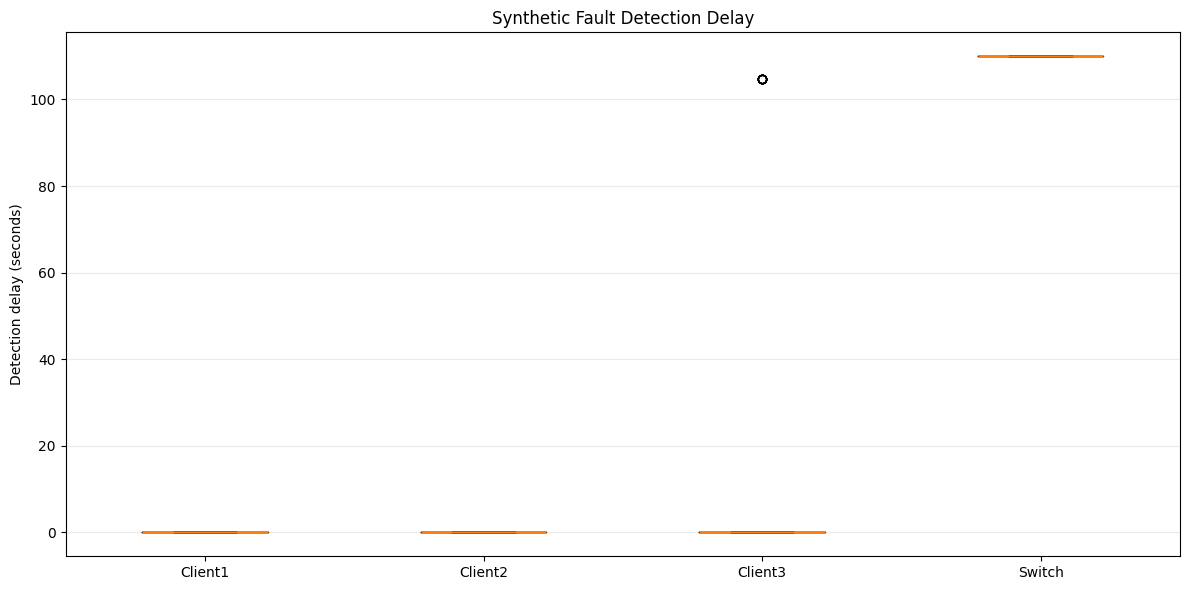


10.8 — Device evaluation
 Device  Test_Samples  Anomalous_Samples  Anomaly_Rate_Pct  Threshold  Mean_Score  Maximum_Score  Total_Events  Experiments  Newly_Detected  Mean_Detection_Delay_Seconds  Synthetic_Detection_Pct
Client1         11746                208          1.770816  90.225526  -53.106847     265.833794           134          180             120                      0.000000                66.666667
Client2         11720                525          4.479522 116.169015   34.082859     233.168251           204          180             105                      0.000000                58.333333
Client3         10983                537          4.889374  96.410350   37.346488     234.993960           416          180             128                      6.550017                71.111111
 Switch         14377              13233         92.042846 243.022655  349.425467     496.622474           351           45               6                    110.000000                13.333333

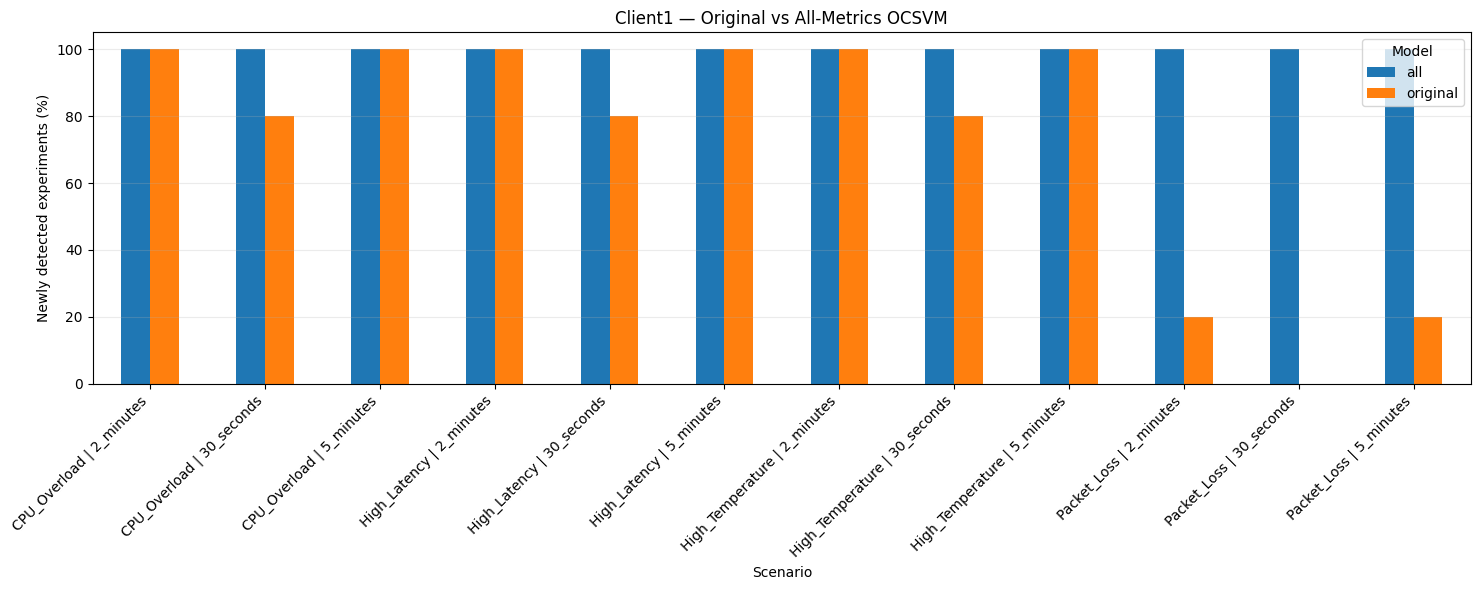

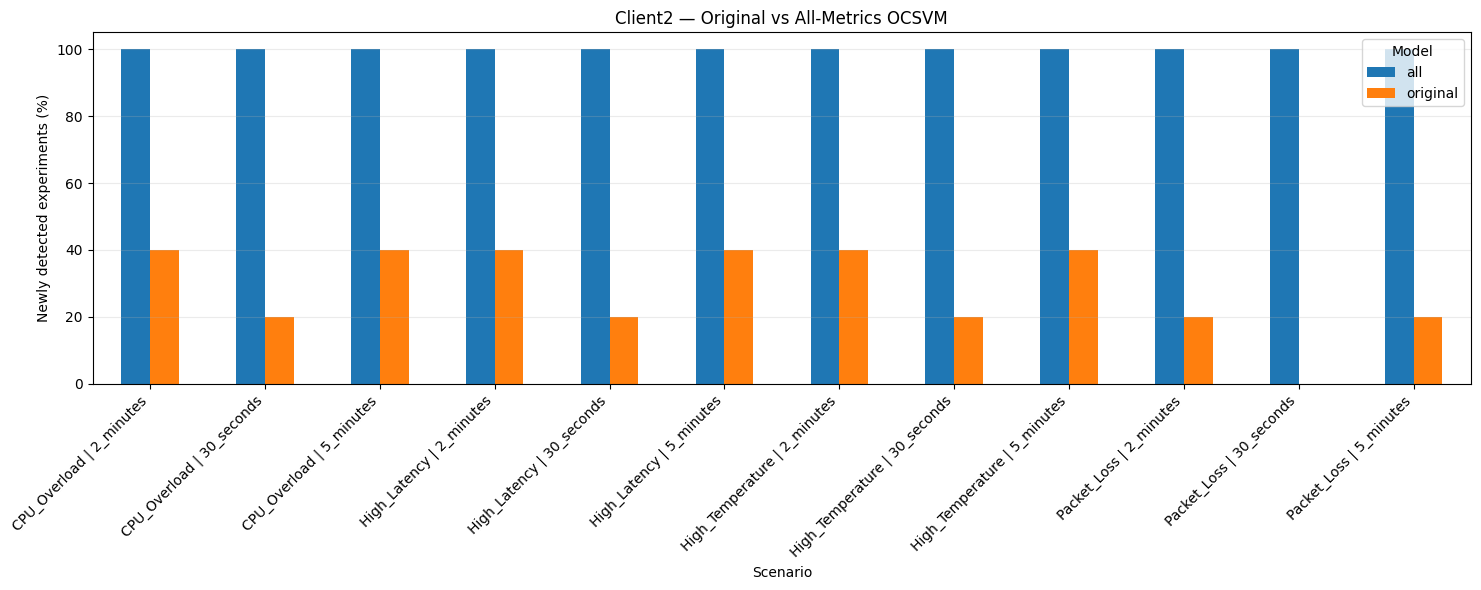

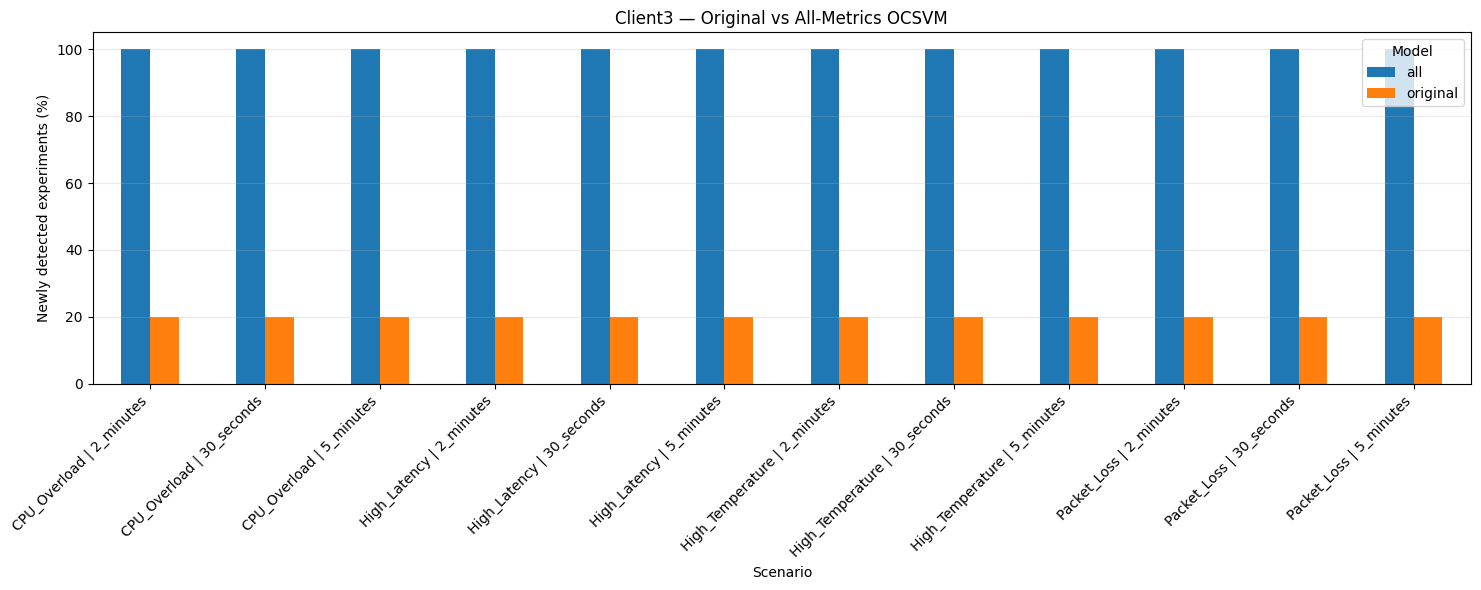

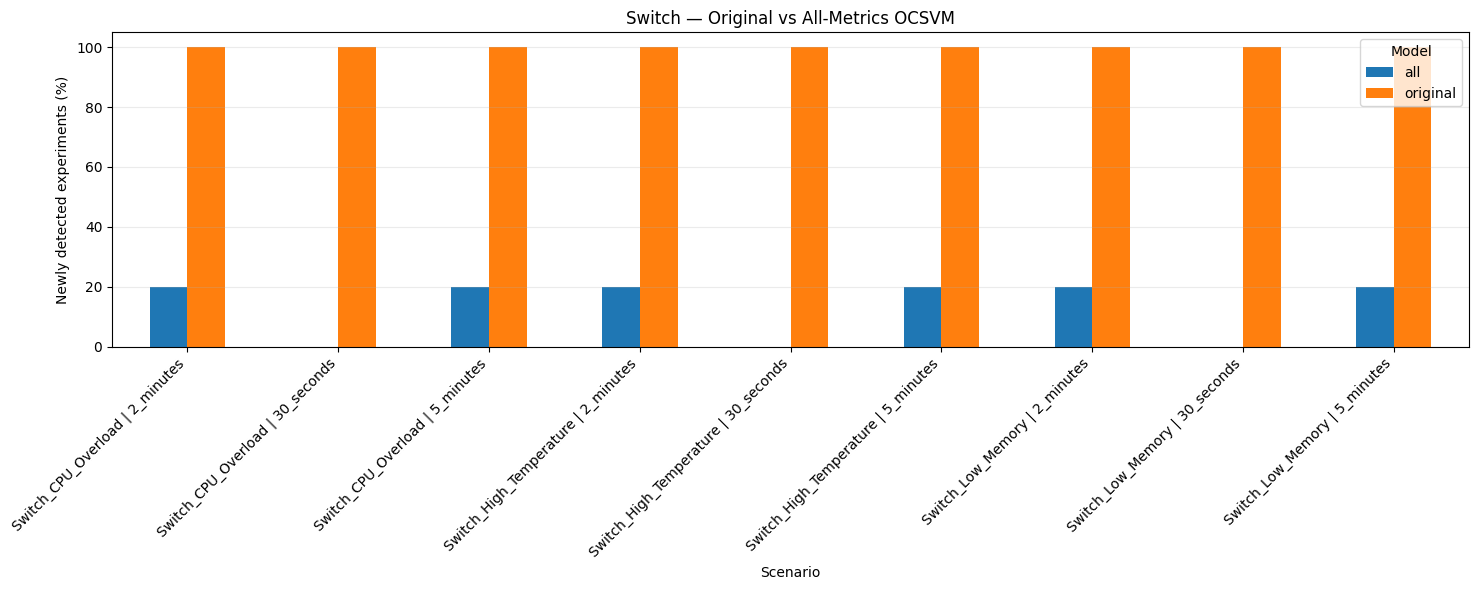


FINAL ALL-METRICS OCSVM RESULTS

Synthetic experiments: 585
Newly detected experiments: 359
Synthetic detection rate: 61.37%

Results directory:
C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\OCSVM_All_Metrics_Results\Final_Evaluation

SECTION 10 COMPLETE


In [46]:
# ============================================================
# SECTION 10 — FINAL OCSVM EVALUATION
# ORIGINAL AND ALL-METRICS MODELS
# ============================================================

BOX_DIR = EVAL_DIR / "Box_Plots"
TABLE_DIR = EVAL_DIR / "Tables"
COMPARE_DIR = EVAL_DIR / "Model_Comparison"

for folder in [BOX_DIR, TABLE_DIR, COMPARE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ============================================================
# 10.1 TELEMETRY BOX PLOTS
# ============================================================

print("\n10.1 — Telemetry box plots")

for device in DEVICES:

    df = datasets[device]
    features = device_metrics[device]

    rows = int(np.ceil(len(features) / 3))

    fig, axes = plt.subplots(
        rows, 3,
        figsize=(18, rows * 3.6),
        squeeze=False
    )

    axes = axes.flatten()

    for i, feature in enumerate(features):

        values = pd.to_numeric(
            df[feature], errors="coerce"
        ).replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        if not values.empty:
            axes[i].boxplot([values], showfliers=True)

        axes[i].set_title(feature)
        axes[i].set_ylabel("Recorded value")
        axes[i].set_xticks([])
        axes[i].grid(axis="y", alpha=0.25)

    for ax in axes[len(features):]:
        ax.set_visible(False)

    fig.suptitle(
        f"{device} — {MODEL_TYPE} Telemetry",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        BOX_DIR / f"{device}_Telemetry_Boxplots.png",
        dpi=180
    )

    plt.show()
    plt.close()

# ============================================================
# 10.2 STANDARDISED FEATURE DEVIATIONS
# ============================================================

print("\n10.2 — Per-feature deviation box plots")

for device in DEVICES:

    df = anomaly_results[device]

    columns = [
        col for col in df.columns
        if col.endswith("_abs_z")
        and col != "most_unusual_metric_abs_z"
    ]

    if not columns:
        continue

    rows = int(np.ceil(len(columns) / 3))

    fig, axes = plt.subplots(
        rows, 3,
        figsize=(18, rows * 3.6),
        squeeze=False
    )

    axes = axes.flatten()

    for i, col in enumerate(columns):

        values = pd.to_numeric(
            df[col], errors="coerce"
        ).dropna()

        if not values.empty:
            axes[i].boxplot([values], showfliers=True)

        axes[i].set_title(
            col.removesuffix("_abs_z")
        )

        axes[i].set_ylabel("Absolute z-score")
        axes[i].set_xticks([])
        axes[i].grid(axis="y", alpha=0.25)

    for ax in axes[len(columns):]:
        ax.set_visible(False)

    fig.suptitle(
        f"{device} — Feature Deviations",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        BOX_DIR / f"{device}_Feature_Deviations.png",
        dpi=180
    )

    plt.show()
    plt.close()

# ============================================================
# 10.3 ANOMALY-SCORE DISTRIBUTIONS
# ============================================================

print("\n10.3 — Anomaly-score box plots")

fig, axes = plt.subplots(
    2, 2, figsize=(14, 10)
)

for ax, device in zip(axes.flatten(), DEVICES):

    df = anomaly_results[device]

    normal = df.loc[
        ~df["is_anomaly"], "anomaly_score"
    ].dropna()

    anomalous = df.loc[
        df["is_anomaly"], "anomaly_score"
    ].dropna()

    groups = []
    labels = []

    if len(normal):
        groups.append(normal)
        labels.append("Not flagged")

    if len(anomalous):
        groups.append(anomalous)
        labels.append("Flagged")

    if groups:
        ax.boxplot(
            groups,
            tick_labels=labels,
            showfliers=True
        )

    ax.axhline(
        anomaly_thresholds[device],
        color="red",
        linestyle="--",
        label="Threshold"
    )

    ax.set_title(device)
    ax.set_ylabel("OCSVM anomaly score")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    f"{MODEL_TYPE.title()}-Metrics OCSVM — Anomaly Scores"
)

plt.tight_layout()

plt.savefig(
    BOX_DIR / "Anomaly_Score_Boxplots.png",
    dpi=180
)

plt.show()
plt.close()

# ============================================================
# 10.4 ANOMALY-SCORE MARGIN COMPARISON
# ============================================================

print("\n10.4 — Threshold-centred scores")

margins = [
    anomaly_results[device]["anomaly_score"].to_numpy()
    - anomaly_thresholds[device]
    for device in DEVICES
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.boxplot(
    margins,
    tick_labels=DEVICES,
    showfliers=True
)

ax.axhline(
    0,
    color="red",
    linestyle="--",
    label="Anomaly boundary"
)

ax.set_title("OCSVM Score Relative to Threshold")
ax.set_ylabel("Anomaly score − threshold")
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    BOX_DIR / "Threshold_Margin_Boxplots.png",
    dpi=180
)

plt.show()
plt.close()

# ============================================================
# 10.5 FAULT-INJECTION SCORE BOX PLOTS
# ============================================================

print("\n10.5 — Fault injection score box plots")

required_columns = [
    "Device",
    "Fault",
    "original_score",
    "injected_score"
]

missing = [
    col for col in required_columns
    if col not in fault_observations_df.columns
]

if missing or fault_observations_df.empty:

    print(
        "Fault observation plots unavailable.",
        "Missing columns:", missing
    )

else:

    for device in DEVICES:

        sub = fault_observations_df.loc[
            fault_observations_df["Device"] == device
        ]

        if sub.empty:
            continue

        faults = sorted(
            sub["Fault"].dropna().unique()
        )

        if not faults:
            continue

        rows = int(np.ceil(len(faults) / 2))

        fig, axes = plt.subplots(
            rows, 2,
            figsize=(15, rows * 4),
            squeeze=False
        )

        axes = axes.flatten()

        for i, fault in enumerate(faults):

            group = sub.loc[
                sub["Fault"] == fault
            ]

            original_scores = pd.to_numeric(
                group["original_score"],
                errors="coerce"
            ).dropna()

            injected_scores = pd.to_numeric(
                group["injected_score"],
                errors="coerce"
            ).dropna()

            if original_scores.empty or injected_scores.empty:
                axes[i].set_visible(False)
                continue

            axes[i].boxplot(
                [original_scores, injected_scores],
                tick_labels=["Original", "Injected"],
                showfliers=True
            )

            axes[i].set_title(fault)
            axes[i].set_ylabel("OCSVM anomaly score")
            axes[i].grid(axis="y", alpha=0.25)

        for ax in axes[len(faults):]:
            ax.set_visible(False)

        fig.suptitle(
            f"{device} — Synthetic Fault Scores",
            fontsize=15
        )

        plt.tight_layout()

        plt.savefig(
            BOX_DIR / f"{device}_Fault_Scores.png",
            dpi=180
        )

        plt.show()
        plt.close()

# ============================================================
# 10.6 SYNTHETIC FAULT-DETECTION RATES
# ============================================================

print("\n10.6 — Fault detection rates")

for device in DEVICES:

    sub = fault_summary_df.loc[
        fault_summary_df["Device"] == device
    ]

    if sub.empty:
        continue

    pivot = sub.pivot(
        index="Fault",
        columns="Duration",
        values="New_Detection_Rate_Pct"
    ).reindex(
        columns=list(FAULT_DURATIONS)
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(14, 6)
    )

    ax.set_title(f"{device} — Fault Detection")
    ax.set_ylabel("Newly detected experiments (%)")
    ax.set_ylim(0, 105)
    ax.grid(axis="y", alpha=0.25)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        BOX_DIR / f"{device}_Fault_Detection_Rates.png",
        dpi=180
    )

    plt.show()
    plt.close()

# ============================================================
# 10.7 DETECTION-DELAY BOX PLOTS
# ============================================================

print("\n10.7 — Detection delay")

delay_groups = []
delay_labels = []

for device in DEVICES:

    values = fault_results_df.loc[
        (fault_results_df["Device"] == device)
        & fault_results_df["Newly_Detected_Any"],
        "Detection_Delay_Seconds"
    ].dropna()

    if len(values):
        delay_groups.append(values)
        delay_labels.append(device)

if delay_groups:

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.boxplot(
        delay_groups,
        tick_labels=delay_labels
    )

    ax.set_title("Synthetic Fault Detection Delay")
    ax.set_ylabel("Detection delay (seconds)")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()

    plt.savefig(
        BOX_DIR / "Detection_Delay_Boxplots.png",
        dpi=180
    )

    plt.show()
    plt.close()

# ============================================================
# 10.8 FINAL DEVICE EVALUATION
# ============================================================

print("\n10.8 — Device evaluation")

device_fault_summary = (
    fault_results_df.groupby(
        "Device", as_index=False
    )
    .agg(
        Experiments=("Experiment_ID", "count"),
        Newly_Detected=("Newly_Detected_Any", "sum"),
        Mean_Detection_Delay_Seconds=(
            "Detection_Delay_Seconds", "mean"
        )
    )
)

device_fault_summary["Synthetic_Detection_Pct"] = (
    device_fault_summary["Newly_Detected"]
    / device_fault_summary["Experiments"] * 100
)

final_evaluation = (
    evaluation_df
    .merge(event_summary_df, on="Device", how="left")
    .merge(device_fault_summary, on="Device", how="left")
)

final_evaluation.to_csv(
    TABLE_DIR / "Final_OCSVM_Evaluation.csv",
    index=False
)

print(final_evaluation.to_string(index=False))

# ============================================================
# 10.9 KPI EVALUATION
# ============================================================

print("\n10.9 — Capstone KPIs")

kpi_records = []

for device in DEVICES:

    alerts = anomaly_results[device].loc[
        anomaly_results[device]["is_anomaly"]
    ]

    attributed = int(
        alerts["most_unusual_metric"].notna().sum()
    )

    coverage = (
        attributed / len(alerts) * 100
        if len(alerts) else np.nan
    )

    row = device_fault_summary.loc[
        device_fault_summary["Device"] == device
    ].iloc[0]

    detection_rate = float(
        row["Synthetic_Detection_Pct"]
    )

    kpi_records.append({
        "Device": device,
        "Model": MODEL_TYPE,
        "Synthetic_Detection_Pct": detection_rate,
        "Synthetic_Target_Met": detection_rate >= 85,
        "Explainability_Coverage_Pct": coverage,
        "False_Positive_Rate_Pct": np.nan,
        "Static_Threshold_Outperformance": "Not verified",
        "Data_Completeness_Pct": np.nan
    })

kpi_df = pd.DataFrame(kpi_records)

kpi_df.to_csv(
    TABLE_DIR / "OCSVM_KPI_Evaluation.csv",
    index=False
)

print(kpi_df.to_string(index=False))

# ============================================================
# 10.10 ORIGINAL VS ALL-METRICS OCSVM COMPARISON
# ============================================================

print("\n10.10 — Original vs All-Metrics OCSVM")

OTHER_MODEL_TYPE = (
    "all" if MODEL_TYPE == "original" else "original"
)

OTHER_RESULTS_DIR = (
    BASE_DIR / "OCSVM_All_Metrics_Results"
    if OTHER_MODEL_TYPE == "all"
    else BASE_DIR / "OCSVM_Original_Results"
)

OTHER_FAULT_PATH = (
    OTHER_RESULTS_DIR
    / "Fault_Injection"
    / "OCSVM_Fault_Results.csv"
)

if OTHER_FAULT_PATH.exists():

    other_faults = pd.read_csv(OTHER_FAULT_PATH)

    other_faults["Newly_Detected_Any"] = (
        other_faults["Newly_Detected_Any"]
        .astype(str)
        .str.lower()
        .isin(["true", "1", "yes"])
    )

    current_faults = fault_results_df.copy()

    # --------------------------------------------------------
    # Compare only common device/fault/duration scenarios.
    # --------------------------------------------------------

    keys = ["Device", "Fault", "Duration"]

    shared = current_faults[keys].drop_duplicates().merge(
        other_faults[keys].drop_duplicates(),
        on=keys
    )

    current_common = current_faults.merge(
        shared, on=keys
    )

    other_common = other_faults.merge(
        shared, on=keys
    )

    current_common["Model"] = MODEL_TYPE
    other_common["Model"] = OTHER_MODEL_TYPE

    comparison = pd.concat(
        [current_common, other_common],
        ignore_index=True
    )

    comparison_summary = (
        comparison.groupby(
            keys + ["Model"],
            as_index=False
        )
        .agg(
            Experiments=("Newly_Detected_Any", "count"),
            Newly_Detected=("Newly_Detected_Any", "sum")
        )
    )

    comparison_summary["Detection_Rate_Pct"] = (
        comparison_summary["Newly_Detected"]
        / comparison_summary["Experiments"] * 100
    )

    comparison_summary.to_csv(
        COMPARE_DIR / "Original_vs_All_OCSVM.csv",
        index=False
    )

    # --------------------------------------------------------
    # Exactly matched injections, if available
    # --------------------------------------------------------

    matched = pd.DataFrame()

    pair_keys = [
        "Device", "Fault", "Duration",
        "Injection_Start"
    ]

    if all(
        col in current_common.columns
        and col in other_common.columns
        for col in pair_keys
    ):

        for frame in [current_common, other_common]:
            frame["Injection_Start"] = pd.to_datetime(
                frame["Injection_Start"],
                utc=True,
                errors="coerce"
            )

        if (
            not current_common.duplicated(pair_keys).any()
            and not other_common.duplicated(pair_keys).any()
        ):

            matched = current_common[
                pair_keys + ["Newly_Detected_Any"]
            ].merge(
                other_common[
                    pair_keys + ["Newly_Detected_Any"]
                ],
                on=pair_keys,
                suffixes=(
                    f"_{MODEL_TYPE}",
                    f"_{OTHER_MODEL_TYPE}"
                ),
                validate="one_to_one"
            )

            matched.to_csv(
                COMPARE_DIR / "Matched_OCSVM_Experiments.csv",
                index=False
            )

    print("\nCOMMON-SCENARIO COMPARISON")
    print(comparison_summary.to_string(index=False))

    print("\nExactly matched experiments:", len(matched))

    # --------------------------------------------------------
    # Comparison plots
    # --------------------------------------------------------

    for device in DEVICES:

        sub = comparison_summary.loc[
            comparison_summary["Device"] == device
        ].copy()

        if sub.empty:
            continue

        sub["Scenario"] = (
            sub["Fault"] + " | " + sub["Duration"]
        )

        pivot = sub.pivot(
            index="Scenario",
            columns="Model",
            values="Detection_Rate_Pct"
        )

        ax = pivot.plot(
            kind="bar",
            figsize=(15, 6)
        )

        ax.set_title(
            f"{device} — Original vs All-Metrics OCSVM"
        )

        ax.set_ylabel("Newly detected experiments (%)")
        ax.set_ylim(0, 105)
        ax.grid(axis="y", alpha=0.25)

        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()

        plt.savefig(
            COMPARE_DIR / f"{device}_OCSVM_Comparison.png",
            dpi=180
        )

        plt.show()
        plt.close()

else:

    print(
        "The other OCSVM model's fault results "
        "are not available yet."
    )

# ============================================================
# 10.11 FINAL SUMMARY
# ============================================================

overall_detection_rate = (
    fault_results_df["Newly_Detected_Any"].mean() * 100
)

print("\n" + "=" * 65)
print(f"FINAL {MODEL_TYPE.upper()}-METRICS OCSVM RESULTS")
print("=" * 65)

print("\nSynthetic experiments:", len(fault_results_df))
print(
    "Newly detected experiments:",
    int(fault_results_df["Newly_Detected_Any"].sum())
)
print(
    f"Synthetic detection rate: "
    f"{overall_detection_rate:.2f}%"
)

print("\nResults directory:")
print(EVAL_DIR.resolve())

print("\nSECTION 10 COMPLETE")
